# Proyecto final: simulación y riesgo de un portafolio de inversión

**Simulación de Procesos Financieros | ITESO**

**Autor:** André Esteban

---

## Objetivo

1. Construir y simular un portafolio de inversión con datos reales.
2. Comparar distintos métodos de simulación Monte Carlo.
3. Evaluar el riesgo del portafolio con VaR, CVaR y pruebas de estrés.

## Contenido

1. Selección de activos
2. Análisis exploratorio de datos
3. Modelo y simulación del portafolio (Cholesky, $M = 10{,}000$, $T = 1$)
4. Métodos de reducción de varianza: antitéticas, variable de control y Sobol
5. Pruebas de estrés
6. Conclusiones
7. Extra: optimización de los pesos para un cliente moderado

---

### Librerías

In [1]:
import time
import warnings
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
from scipy import stats, sparse
from scipy.stats import qmc
from scipy.optimize import linprog

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

---

# 1. Selección de activos

El portafolio combina siete activos de sectores y clases distintas. La idea es que no todos respondan a lo mismo: unos dependen del crecimiento económico, otros son defensivos y otros funcionan como refugio en las crisis.

| Ticker | Activo | Sector o clase | Papel en el portafolio |
|---|---|---|---|
| MSFT | Microsoft | Tecnología | Crecimiento; expuesta a la inversión en inteligencia artificial |
| JPM | JPMorgan Chase | Financiero | Ciclo económico y nivel de tasas de interés |
| JNJ | Johnson & Johnson | Salud | Defensivo: la demanda de medicamentos no depende del ciclo |
| COST | Costco | Consumo básico | Defensivo con crecimiento estable |
| XOM | Exxon Mobil | Energía | Precio del petróleo; cobertura parcial contra inflación |
| GLD | SPDR Gold Shares | Oro (ETF) | Refugio en crisis y cobertura contra inflación |
| TLT | iShares 20+ Year Treasury Bond | Bonos del Tesoro de largo plazo (ETF) | Refugio en recesiones; muy sensible a las tasas |

El **S&P 500** (`^GSPC`) no forma parte del portafolio. Se descarga como referencia del mercado y para calcular la beta de cada activo, que se usa en la prueba de estrés de caída general del mercado.

**Inversión inicial:** $V_0 = 100{,}000$ USD. Como punto de partida se usan **pesos iguales** ($1/7 \approx 14.29\%$ por activo), un portafolio neutral que no depende de ninguna estimación. En la sección 7 los pesos se optimizan.

### Activos, inversión inicial y pesos

In [2]:
activos = {
    "MSFT": "Microsoft (tecnología)",
    "JPM":  "JPMorgan Chase (financiero)",
    "JNJ":  "Johnson & Johnson (salud)",
    "COST": "Costco (consumo básico)",
    "XOM":  "Exxon Mobil (energía)",
    "GLD":  "SPDR Gold Shares (oro)",
    "TLT":  "iShares 20+ Year Treasury Bond (bonos)",
}
tickers   = list(activos.keys())
benchmark = "^GSPC"
k = len(tickers)

V0 = 100_000
w  = np.full(k, 1 / k)

pd.DataFrame({"Activo": activos.values(), "Peso (%)": w * 100,
              "Inversión (USD)": w * V0}, index=tickers).round(2)

,Activo,Peso (%),Inversión (USD)
MSFT,Microsoft (tecnología),14.29,14285.71
JPM,JPMorgan Chase (financiero),14.29,14285.71
JNJ,Johnson & Johnson (salud),14.29,14285.71
COST,Costco (consumo básico),14.29,14285.71
XOM,Exxon Mobil (energía),14.29,14285.71
GLD,SPDR Gold Shares (oro),14.29,14285.71
TLT,iShares 20+ Year Treasury Bond (bonos),14.29,14285.71


---

# 2. Análisis exploratorio de datos

Antes de simular, se revisa qué dicen los datos de los últimos tres años: cuánto rindió y cuánto se movió cada activo, qué tan seguido hubo días extremos, cómo se relacionan entre sí y con el mercado. Todo lo que se encuentre aquí alimenta (o pone en duda) los supuestos del modelo.

### Descarga de precios de los últimos 3 años

In [3]:
data = yf.download(tickers + [benchmark], start="2023-11-24", end="2026-11-24",
                   auto_adjust=True, progress=False)

precios_todos = data["Close"][tickers + [benchmark]].dropna()
precios = precios_todos[tickers]
mercado = precios_todos[benchmark]

print(f"Periodo: {precios.index[0].date()} a {precios.index[-1].date()}")
print(f"Observaciones: {len(precios)}")
precios_todos.tail()

Periodo: 2023-11-24 a 2026-11-23
Observaciones: 752


Ticker,MSFT,JPM,JNJ,COST,XOM,GLD,TLT,^GSPC
Date,,,,,,,,
2026-11-17,505.263947,329.959991,277.317108,1079.747437,167.210007,352.480011,79.550003,7340.529785
2026-11-18,507.309998,324.109985,271.346863,1066.655273,160.580002,341.190002,80.220001,7323.629883
2026-11-19,498.299988,320.220001,265.814453,1063.941528,158.929993,335.179993,80.349998,7175.830078
2026-11-20,484.519989,310.529999,269.127930,1072.034180,159.990005,322.869995,81.449997,6910.390137
2026-11-23,492.500000,316.660004,268.709991,1067.910034,156.899994,333.019989,81.690002,7237.169922


### ¿Qué observamos?

Se tienen 752 días con precio para los ocho activos, del 24 de noviembre de 2023 al 23 de noviembre de 2026. Solo se conservan los días en que todos cotizaron, para que los rendimientos de un mismo día sean comparables entre activos.

### Evolución de los precios (base 100)

Cada serie se divide entre su primer precio y se multiplica por 100, para que todas arranquen en el mismo punto. La línea negra gruesa es el portafolio de pesos iguales comprado al inicio y mantenido; la gris punteada es el S&P 500.

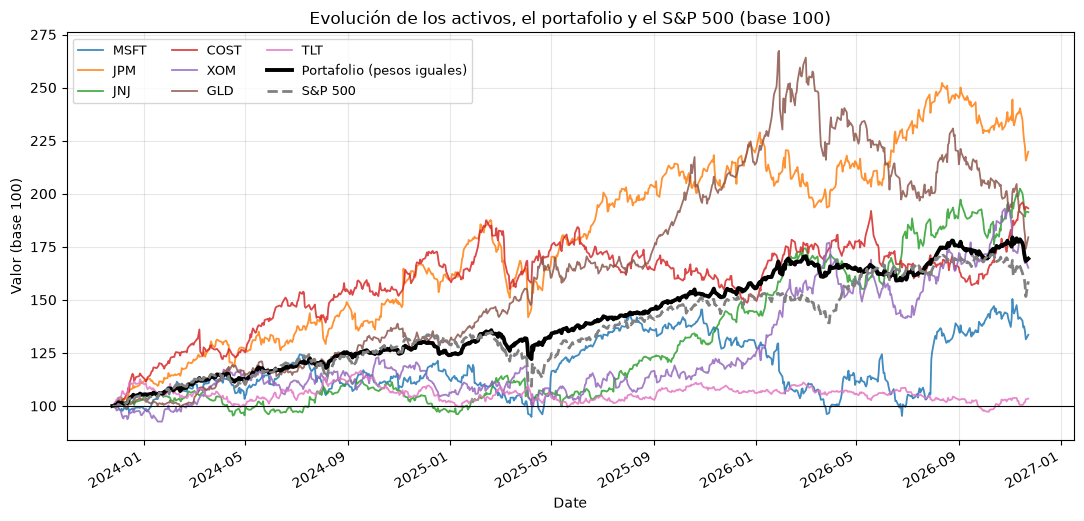

In [4]:
port_hist = (precios / precios.iloc[0]) @ w * 100

fig, ax = plt.subplots(figsize=(13, 6))
(precios / precios.iloc[0] * 100).plot(ax=ax, lw=1.3, alpha=0.85)
port_hist.plot(ax=ax, color="black", lw=2.8, label="Portafolio (pesos iguales)")
(mercado / mercado.iloc[0] * 100).plot(ax=ax, color="gray", ls="--", lw=2, label="S&P 500")
ax.axhline(100, color="black", lw=0.8)
ax.set_title("Evolución de los activos, el portafolio y el S&P 500 (base 100)")
ax.set_ylabel("Valor (base 100)")
ax.legend(ncol=3, fontsize=9)
plt.show()

### ¿Qué observamos?

- **Fueron tres años muy buenos para casi todos los activos.** JPM más que duplicó su valor (alrededor de +120%), GLD llegó a subir más de 160% a principios de 2026 antes de retroceder, y JNJ, COST y XOM subieron entre 65% y 95%.
- **Las excepciones son MSFT y TLT.** MSFT subió solo alrededor de 34%, con mucha volatilidad en 2026, y TLT terminó prácticamente donde empezó (alrededor de +3.5%): los bonos de largo plazo casi no generaron rendimiento en el periodo.
- **El portafolio de pesos iguales (alrededor de +69%) le ganó al S&P 500 (alrededor de +59%) con una trayectoria mucho más suave.** La línea negra casi no tiene caídas fuertes, aunque varios de sus componentes sí las tuvieron. Es el primer indicio de que la diversificación está funcionando.

### Estadística descriptiva de los rendimientos logarítmicos diarios

- **Rendimiento y volatilidad anual:** media y desviación de los rendimientos diarios, anualizadas con 252 días.
- **Rend. / Vol.:** cuánto rendimiento se obtuvo por cada unidad de riesgo.
- **Asimetría:** negativa si las caídas fuertes son más comunes que las subidas fuertes.
- **Curtosis (exceso):** 0 en una normal; si es positiva, hay más días extremos de los que predice la normal.
- **Máxima caída:** la peor pérdida desde un máximo previo hasta un mínimo posterior.

In [5]:
series = precios.copy()
series["Portafolio"] = port_hist
series["S&P 500"] = mercado

log_ret_todos = np.log(series / series.shift(1)).dropna()
log_ret = log_ret_todos[tickers]

def max_drawdown(serie):
    return (serie / serie.cummax() - 1).min()

descriptiva = pd.DataFrame({
    "Rend. anual log (%)": log_ret_todos.mean() * 252 * 100,
    "Volatilidad anual (%)": log_ret_todos.std() * np.sqrt(252) * 100,
    "Rend. / Vol.": (log_ret_todos.mean() * 252) / (log_ret_todos.std() * np.sqrt(252)),
    "Peor día (%)": log_ret_todos.min() * 100,
    "Mejor día (%)": log_ret_todos.max() * 100,
    "Asimetría": log_ret_todos.skew(),
    "Curtosis (exceso)": log_ret_todos.kurt(),
    "Máx. caída (%)": series.apply(max_drawdown) * 100,
})
descriptiva.round(2)

,Rend. anual log (%),Volatilidad anual (%),Rend. / Vol.,Peor día (%),Mejor día (%),Asimetría,Curtosis (exceso),Máx. caída (%)
Ticker,,,,,,,,
MSFT,9.70,26.46,0.37,-10.53,14.42,0.74,11.54,-34.50
JPM,26.42,23.50,1.12,-7.78,10.93,-0.20,7.28,-24.42
JNJ,21.77,18.81,1.16,-7.90,6.01,-0.25,4.74,-14.45
COST,22.08,20.54,1.08,-7.95,6.03,-0.55,3.82,-20.74
XOM,16.83,23.66,0.71,-7.47,4.87,-0.50,1.65,-20.11
GLD,19.63,22.35,0.88,-10.84,6.16,-0.92,6.16,-34.89
TLT,1.14,12.53,0.09,-3.06,3.07,-0.10,0.85,-16.59
Portafolio,17.69,10.39,1.70,-4.38,4.91,-0.07,7.06,-10.03
S&P 500,15.50,15.62,0.99,-6.16,9.09,0.23,13.53,-18.90


### ¿Qué observamos?

- **El portafolio es menos volátil que cualquiera de sus activos.** Su volatilidad anual es de 10.4%, menor incluso que la de TLT (12.5%), el activo más estable, y bastante menor que la del S&P 500 (15.6%). Por eso tiene la mejor relación rendimiento / volatilidad de la tabla (1.70, contra 0.99 del S&P 500).
- **Su peor caída desde un máximo fue de solo 10%**, contra 19% del S&P 500 y alrededor de 35% de MSFT y de GLD.
- **Todos los activos tienen curtosis positiva**, es decir, más días extremos que los que predice una normal. MSFT y el S&P 500 son los casos más marcados (curtosis de 11.5 y 13.5), con días de hasta +14.4% y -10.5% en MSFT.
- **GLD tiene la asimetría más negativa (-0.92):** sus caídas fuertes fueron más violentas que sus subidas, con un peor día de -10.8%. El oro se comportó como un refugio con riesgo propio, no como un activo seguro.
- **TLT rindió apenas 1.1% anual.** En estos tres años no cumplió su papel de generar rendimiento, aunque sí el de bajar la volatilidad.

### Riesgo contra rendimiento histórico

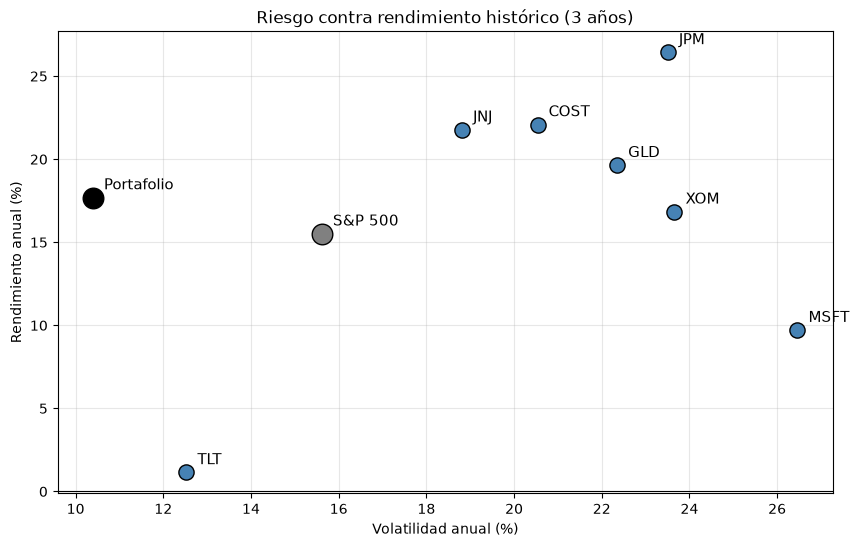

In [6]:
fig, ax = plt.subplots(figsize=(10, 6))
for nombre, fila in descriptiva.iterrows():
    destacado = nombre in ["Portafolio", "S&P 500"]
    ax.scatter(fila["Volatilidad anual (%)"], fila["Rend. anual log (%)"],
               s=220 if destacado else 120, edgecolor="black", zorder=3,
               color="black" if nombre == "Portafolio" else
                     ("gray" if nombre == "S&P 500" else "steelblue"))
    ax.annotate(nombre, (fila["Volatilidad anual (%)"], fila["Rend. anual log (%)"]),
                textcoords="offset points", xytext=(8, 6), fontsize=11)

ax.axhline(0, color="black", lw=0.8)
ax.set_xlabel("Volatilidad anual (%)")
ax.set_ylabel("Rendimiento anual (%)")
ax.set_title("Riesgo contra rendimiento histórico (3 años)")
plt.show()

### ¿Qué observamos?

El portafolio queda **arriba a la izquierda de todos sus componentes**: rinde más que el promedio de sus activos con menos riesgo que cualquiera de ellos. Es la imagen clásica de la diversificación. También se ve que, en este periodo, el riesgo no se pagó de forma ordenada: MSFT fue el activo más volátil y uno de los que menos rindió, mientras que JNJ y COST rindieron más de 20% anual con volatilidad moderada.

### Caídas desde el máximo (drawdown)

Muestra, en cada día, cuánto estaba cada serie por debajo de su máximo previo. Es la forma en que un inversionista vive el riesgo: no como una desviación estándar, sino como "cuánto llegué a perder".

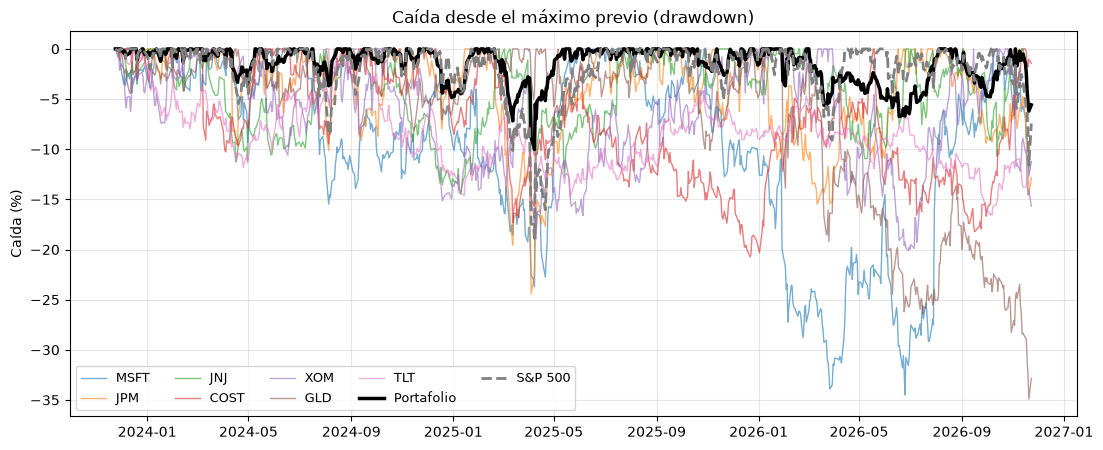

In [7]:
caidas = series / series.cummax() - 1

fig, ax = plt.subplots(figsize=(13, 5))
for t in tickers:
    ax.plot(caidas[t] * 100, lw=1, alpha=0.6, label=t)
ax.plot(caidas["Portafolio"] * 100, color="black", lw=2.5, label="Portafolio")
ax.plot(caidas["S&P 500"] * 100, color="gray", ls="--", lw=2, label="S&P 500")
ax.set_title("Caída desde el máximo previo (drawdown)")
ax.set_ylabel("Caída (%)")
ax.legend(ncol=5, fontsize=9)
plt.show()

### ¿Qué observamos?

- **La peor caída del portafolio (alrededor de 10%) ocurrió en abril de 2025**, durante la caída del mercado por los anuncios de aranceles en Estados Unidos, cuando el S&P 500 llegó a caer casi 19%. Fue el momento en que más activos cayeron al mismo tiempo.
- **Las caídas más profundas de los activos individuales no coincidieron entre sí.** MSFT llegó a estar 34% abajo en 2026 y GLD 35% abajo a finales de 2026, pero en momentos en los que otros activos no caían. Por eso el portafolio nunca pasó de -10%.

### ¿Los rendimientos son normales? Colas pesadas

El modelo de simulación supone rendimientos normales. Aquí se compara la distribución real de los rendimientos diarios contra una normal con la misma media y desviación, y se cuentan los días con movimientos mayores a 3 desviaciones estándar. En una normal, solo el 0.27% de los días debería estar ahí.

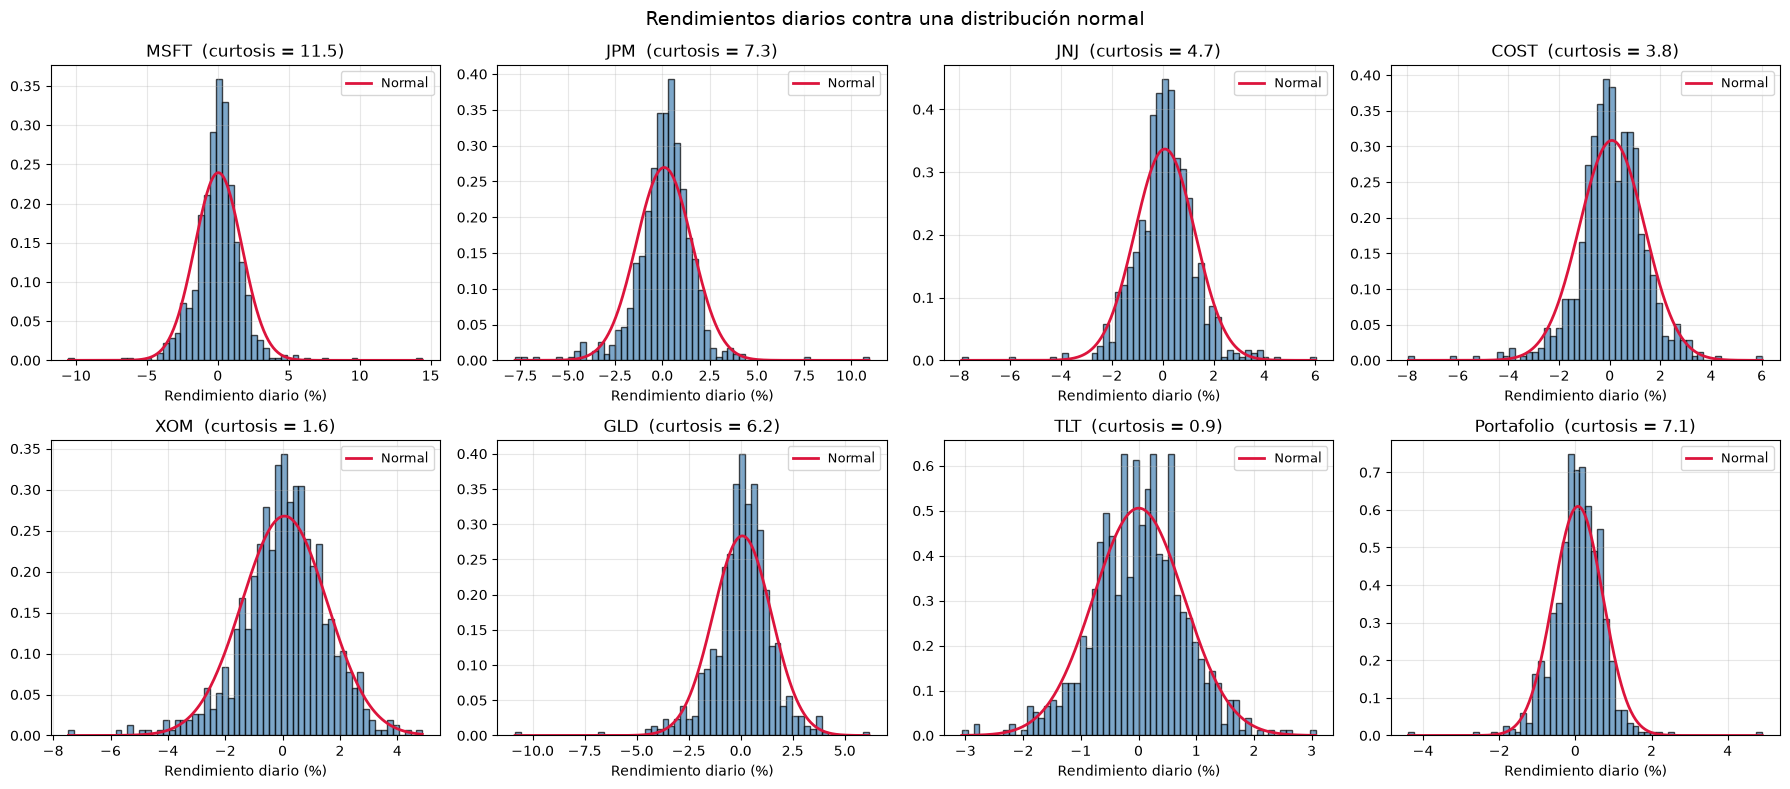

,Días con |r| > 3σ,Esperados si fuera normal,Veces más de lo normal
Ticker,,,
MSFT,10,2.03,4.93
JPM,10,2.03,4.93
JNJ,11,2.03,5.43
COST,10,2.03,4.93
XOM,7,2.03,3.45
GLD,7,2.03,3.45
TLT,6,2.03,2.96
Portafolio,7,2.03,3.45
S&P 500,10,2.03,4.93


In [8]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))

for ax, nombre in zip(axes.flat, tickers + ["Portafolio"]):
    datos = log_ret_todos[nombre] * 100
    x = np.linspace(datos.min(), datos.max(), 300)
    ax.hist(datos, bins=60, density=True, color="steelblue", edgecolor="black", alpha=0.7)
    ax.plot(x, stats.norm.pdf(x, datos.mean(), datos.std()), color="crimson", lw=2,
            label="Normal")
    ax.set_title(f"{nombre}  (curtosis = {datos.kurt():.1f})")
    ax.set_xlabel("Rendimiento diario (%)")
    ax.legend(fontsize=9)

plt.suptitle("Rendimientos diarios contra una distribución normal", fontsize=14)
plt.tight_layout()
plt.show()

n_dias = len(log_ret_todos)
excesos = pd.DataFrame({
    "Días con |r| > 3σ": ((log_ret_todos - log_ret_todos.mean()).abs()
                          > 3 * log_ret_todos.std()).sum(),
    "Esperados si fuera normal": n_dias * 2 * stats.norm.sf(3),
})
excesos["Veces más de lo normal"] = excesos.iloc[:, 0] / excesos.iloc[:, 1]
excesos.round(2)

### ¿Qué observamos?

- **Ningún activo es normal.** Los histogramas tienen un pico más alto y colas más largas que la curva roja: hay muchos días tranquilos y, a la vez, más días extremos de los que la normal permite.
- **Los días con movimientos mayores a 3σ fueron entre 3 y 5.4 veces más frecuentes de lo esperado.** Con una normal se esperarían 2 días en todo el periodo; MSFT, JPM y COST tuvieron 10 cada uno, y JNJ 11.
- **Diversificar baja la volatilidad, pero no elimina las colas.** El portafolio también tiene curtosis alta (7.1) y 3.5 veces más días extremos de lo normal.

**Implicación para el modelo:** la simulación supone rendimientos normales (lognormales en el precio), así que va a **subestimar la frecuencia de los movimientos extremos**. Esta es una de las razones para complementar el VaR con pruebas de estrés en la sección 5.

### Matriz de correlación

La correlación es la pieza que define cuánto sirve la diversificación: entre más baja, más se compensan los movimientos de los activos.

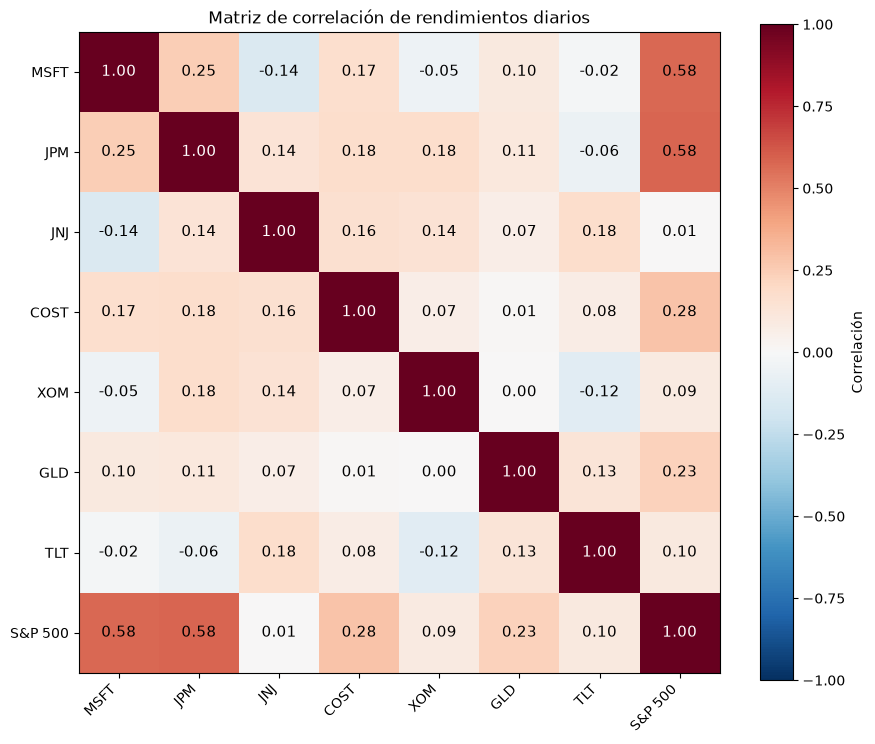

Correlación promedio entre los 7 activos: 0.075


In [9]:
correlacion = log_ret_todos[tickers + ["S&P 500"]].corr()
etiquetas = list(correlacion.columns)

fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(correlacion.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(etiquetas)))
ax.set_xticklabels(etiquetas, rotation=45, ha="right")
ax.set_yticks(range(len(etiquetas)))
ax.set_yticklabels(etiquetas)
ax.grid(False)
for i in range(len(etiquetas)):
    for j in range(len(etiquetas)):
        valor = correlacion.values[i, j]
        ax.text(j, i, f"{valor:.2f}", ha="center", va="center", fontsize=11,
                color="white" if abs(valor) > 0.6 else "black")
plt.colorbar(im, ax=ax, label="Correlación")
ax.set_title("Matriz de correlación de rendimientos diarios")
plt.tight_layout()
plt.show()

corr_activos = correlacion.loc[tickers, tickers].values
print(f"Correlación promedio entre los 7 activos: "
      f"{corr_activos[np.triu_indices(k, 1)].mean():.3f}")

### ¿Qué observamos?

- **Las correlaciones entre los siete activos son muy bajas: en promedio 0.075.** La más alta es MSFT con JPM (0.25), y hay varias negativas: MSFT con JNJ (-0.14) y XOM con TLT (-0.12).
- **Solo MSFT y JPM están realmente ligados al mercado** (correlación de 0.58 con el S&P 500). JNJ (0.01), XOM (0.09) y TLT (0.10) casi no se mueven con él.
- Con correlaciones tan bajas, los movimientos de un activo se compensan con los de otros, y eso explica por qué el portafolio tiene la mitad de la volatilidad promedio de sus componentes.

### Volatilidad y correlación móviles (60 días)

El modelo usa una sola volatilidad y una sola correlación para todo el periodo. Las ventanas móviles muestran qué tan estables son en realidad.

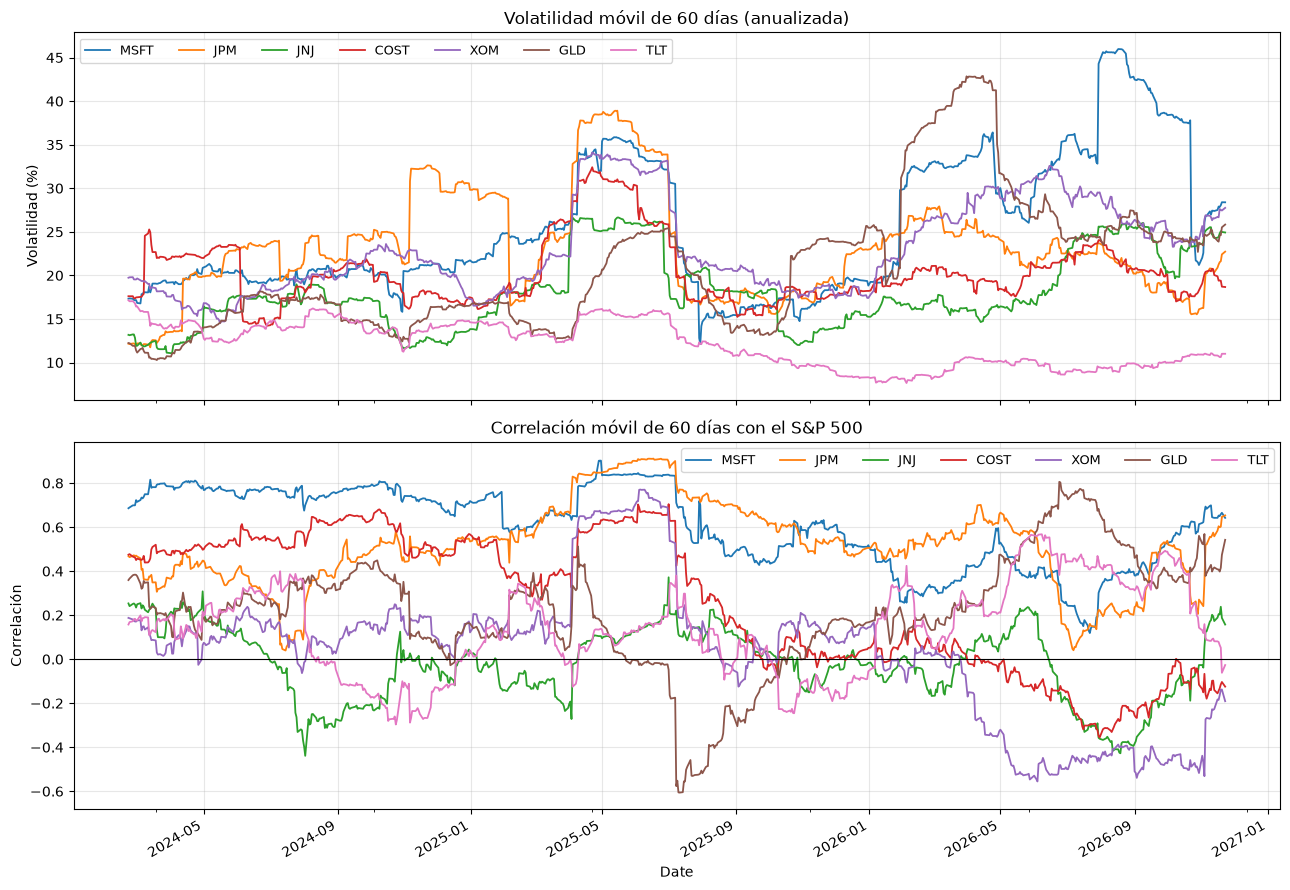

,Vol. mínima (%),Vol. máxima (%),Máx / mín
Ticker,,,
MSFT,12.13,45.98,3.79
JPM,11.74,38.90,3.31
JNJ,11.06,26.64,2.41
COST,14.21,32.41,2.28
XOM,14.51,34.11,2.35
GLD,10.28,42.89,4.17
TLT,7.65,17.14,2.24


In [10]:
ventana = 60
vol_movil  = log_ret.rolling(ventana).std() * np.sqrt(252) * 100
corr_movil = log_ret.rolling(ventana).corr(log_ret_todos["S&P 500"])

fig, axes = plt.subplots(2, 1, figsize=(13, 9), sharex=True)
vol_movil.plot(ax=axes[0], lw=1.3)
axes[0].set_title(f"Volatilidad móvil de {ventana} días (anualizada)")
axes[0].set_ylabel("Volatilidad (%)")
axes[0].legend(ncol=7, fontsize=9)

corr_movil.plot(ax=axes[1], lw=1.3)
axes[1].axhline(0, color="black", lw=0.8)
axes[1].set_title(f"Correlación móvil de {ventana} días con el S&P 500")
axes[1].set_ylabel("Correlación")
axes[1].legend(ncol=7, fontsize=9)
plt.tight_layout()
plt.show()

pd.DataFrame({"Vol. mínima (%)": vol_movil.min(), "Vol. máxima (%)": vol_movil.max(),
              "Máx / mín": vol_movil.max() / vol_movil.min()}).round(2)

### ¿Qué observamos?

- **La volatilidad cambia mucho con el tiempo.** El cociente entre la volatilidad máxima y la mínima va de 2.2 veces (TLT, COST) a 4.2 veces (GLD, que pasó de 10% a 43%). Usar una sola volatilidad para todo el año es una simplificación fuerte.
- **En abril de 2025 la volatilidad de casi todos los activos subió al mismo tiempo**, y la correlación con el S&P 500 se disparó: MSFT y JPM llegaron a 0.9, XOM a 0.75 y COST a 0.7. Es el fenómeno clásico de las crisis: **cuando el mercado cae, las correlaciones suben y la diversificación protege menos justo cuando más se necesita.**
- **Las correlaciones de los activos defensivos también cambian de signo.** GLD pasó de -0.6 a 0.8 con el S&P 500, y XOM se movió en sentido contrario al mercado durante buena parte de 2026.

Estos dos hechos justifican los escenarios de doble volatilidad y de colapso de la diversificación.

### Beta de cada activo contra el S&P 500

$$\beta_i = \frac{\text{Cov}(r_i, r_m)}{\text{Var}(r_m)}$$

La beta mide cuánto se mueve un activo cuando se mueve el mercado: con $\beta = 1.2$, si el S&P cae 10% el activo tiende a caer 12%. La $R^2$ indica qué parte de la variación del activo se explica por el mercado.

In [11]:
ret_m = log_ret_todos["S&P 500"]

betas = pd.DataFrame(index=tickers + ["Portafolio"])
betas["Beta"] = [np.cov(log_ret_todos[t], ret_m)[0, 1] / ret_m.var() for t in betas.index]
betas["Correlación con S&P"] = [log_ret_todos[t].corr(ret_m) for t in betas.index]
betas["R² (% explicado por el mercado)"] = betas["Correlación con S&P"] ** 2 * 100
betas.round(3)

,Beta,Correlación con S&P,R² (% explicado por el mercado)
MSFT,0.979,0.578,33.390
JPM,0.877,0.583,33.983
JNJ,0.009,0.008,0.006
COST,0.371,0.282,7.955
XOM,0.142,0.093,0.873
GLD,0.331,0.231,5.341
TLT,0.080,0.100,0.998
Portafolio,0.420,0.631,39.802


### ¿Qué observamos?

- **MSFT (0.98) y JPM (0.88) son los activos de mercado del portafolio:** se mueven casi uno a uno con el S&P 500, y el mercado explica alrededor de un tercio de su variación.
- **JNJ (0.01), TLT (0.08) y XOM (0.14) tienen beta casi nula:** su riesgo es casi todo propio de cada empresa o sector, y se diversifica dentro del portafolio.
- **El portafolio tiene una beta de 0.42:** si el mercado cae 10%, se espera que el portafolio caiga alrededor de 4%. Aun así, el mercado explica el 40% de su variación, más que en cualquier activo individual, porque al combinarlos el riesgo propio de cada uno se cancela y lo que queda es, sobre todo, riesgo de mercado.

### Resumen del análisis exploratorio

1. **El periodo fue excepcionalmente alcista.** Seis de los siete activos rindieron entre 9.7% y 26.4% anual (logarítmico), y el portafolio 17.7%. Esto es importante para el modelo: extrapolar estos rendimientos al próximo año sería muy optimista.
2. **La diversificación funciona muy bien con estos activos.** La correlación promedio es de 0.075, la volatilidad del portafolio (10.4%) es menor que la de cualquier componente y su peor caída fue de 10%.
3. **Los rendimientos tienen colas pesadas.** Los días extremos son de 3 a 5 veces más frecuentes de lo que supone una normal.
4. **La volatilidad y la correlación no son constantes.** En la crisis de abril de 2025 subieron juntas. El modelo, que las supone fijas, no captura ese efecto; las pruebas de estrés sí.
5. **El riesgo de mercado se concentra en MSFT y JPM**, los únicos activos con beta cercana a 1.

---

# 3. Modelo y simulación del portafolio

### Movimiento browniano geométrico multivariado

Cada precio se simula directamente a un año:

$$S_i(T) = S_i(0)\, \exp\left[\left(\mu_i - \tfrac{1}{2}\Sigma_{ii}\right)T + \sqrt{T}\, Z_i\right], \qquad Z = L\,\varepsilon, \quad \varepsilon \sim N(0, I)$$

- $\mu_i$: tendencia anual del precio. Primero se estima con los 3 años de datos históricos ($\mu_i = \bar{r}_i \cdot 252 + \tfrac{1}{2}\sigma_i^2$, donde $\bar{r}_i$ es el promedio de los rendimientos logarítmicos). Como se verá, esa estimación resulta demasiado optimista, y la simulación base usa en su lugar el rendimiento esperado del modelo CAPM.
- $\Sigma$: matriz de covarianzas anualizada; su diagonal son las varianzas $\sigma_i^2$.
- $L$: factor de Cholesky, $\Sigma = L\,L^T$. Convierte choques independientes $\varepsilon$ en choques $Z$ con la correlación histórica, porque $\text{Cov}(L\varepsilon) = L\,I\,L^T = \Sigma$.

Con este modelo, el precio esperado de cada activo es $E[S_i(T)] = S_i(0)\, e^{\mu_i T}$.

### Portafolio

Se compran $N_i = \dfrac{w_i\, V_0}{S_i(0)}$ acciones de cada activo (en fracciones, para respetar los pesos exactos). El valor final y su valor esperado son:

$$V_T = \sum_i N_i\, S_i(T) \qquad E[V_T] = V_0 \sum_i w_i\, e^{\mu_i T}$$

Como $E[V_T]$ tiene fórmula cerrada, se puede medir el error real de cada método de simulación en la sección 4.

### Parámetros anualizados con los datos históricos

In [12]:
Sigma = (log_ret.cov() * 252).values         # matriz de covarianzas anualizada
sigma = np.sqrt(np.diag(Sigma))
mu_hist = log_ret.mean() * 252 + 0.5 * sigma**2   # tendencia histórica del precio
S0 = precios.iloc[-1]

T = 1
M = 10_000

pd.DataFrame({"S0": S0, "sigma": sigma, "mu histórico": mu_hist,
              "E[S_T] / S0 con mu histórico": np.exp(mu_hist * T)}).round(4)

,S0,sigma,mu histórico,E[S_T] / S0 con mu histórico
Ticker,,,,
MSFT,492.50,0.2646,0.1320,1.1412
JPM,316.66,0.2350,0.2919,1.3389
JNJ,268.71,0.1881,0.2354,1.2654
COST,1067.91,0.2054,0.2419,1.2737
XOM,156.90,0.2366,0.1963,1.2168
GLD,333.02,0.2235,0.2213,1.2477
TLT,81.69,0.1253,0.0193,1.0194


### ¿Qué observamos?

- Las volatilidades anuales van de 12.5% (TLT) a 26.5% (MSFT).
- Con la tendencia histórica, el modelo esperaría que cinco de los siete activos subieran entre 20% y 34% en un año (por ejemplo, JPM 33.9% y COST 27.4%), y que el portafolio completo subiera más de 20%. Son cifras muy altas para un portafolio con 10% de volatilidad, y la primera simulación muestra el problema.

### Descomposición de Cholesky

Cholesky solo existe si $\Sigma$ es **definida positiva**, es decir, si todos sus eigenvalores son mayores que cero.

In [13]:
L = np.linalg.cholesky(Sigma)

print("Eigenvalores de Σ (todos deben ser positivos):")
print(np.linalg.eigvalsh(Sigma).round(5))
print(f"\n¿L · Lᵀ reconstruye Σ? {np.allclose(L @ L.T, Sigma)}")
print("\nMatriz L (triangular inferior):")
pd.DataFrame(L, index=tickers, columns=tickers).round(4)

Eigenvalores de Σ (todos deben ser positivos):
[0.01387 0.02771 0.03806 0.04315 0.04987 0.06597 0.08579]

¿L · Lᵀ reconstruye Σ? True

Matriz L (triangular inferior):


,MSFT,JPM,JNJ,COST,XOM,GLD,TLT
MSFT,0.2646,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
JPM,0.0586,0.2276,0.0000,0.0000,0.0000,0.0000,0.0000
JNJ,-0.0267,0.0334,0.1832,0.0000,0.0000,0.0000,0.0000
COST,0.0350,0.0289,0.0344,0.1973,0.0000,0.0000,0.0000
XOM,-0.0113,0.0458,0.0247,0.0080,0.2304,0.0000,0.0000
GLD,0.0220,0.0186,0.0159,-0.0070,-0.0032,0.2209,0.0000
TLT,-0.0024,-0.0066,0.0236,0.0071,-0.0166,0.0156,0.1205


### ¿Qué observamos?

Los siete eigenvalores son positivos (de 0.014 a 0.086), así que $\Sigma$ es definida positiva y la descomposición existe. La primera fila de $L$ solo tiene la volatilidad de MSFT: el primer activo de la lista no se "mezcla" con ningún otro, y cada activo siguiente combina su propio choque con los de los activos anteriores para reproducir la correlación.

### Acciones compradas de cada activo

In [14]:
N = w * V0 / S0.values

pd.DataFrame({"Peso (%)": w * 100, "Inversión (USD)": w * V0, "S0": S0.values,
              "Acciones": N}, index=tickers).round(4)

,Peso (%),Inversión (USD),S0,Acciones
MSFT,14.2857,14285.7143,492.50,29.0065
JPM,14.2857,14285.7143,316.66,45.1137
JNJ,14.2857,14285.7143,268.71,53.1641
COST,14.2857,14285.7143,1067.91,13.3773
XOM,14.2857,14285.7143,156.90,91.0498
GLD,14.2857,14285.7143,333.02,42.8975
TLT,14.2857,14285.7143,81.69,174.8771


### Funciones de apoyo

- `precios_finales`: simula los precios a un año dados los choques $\varepsilon$. Recibe opcionalmente otra matriz $L$ y otra $\Sigma$, lo que permite reutilizarla en las pruebas de estrés.
- `var_cvar`: calcula el VaR y el CVaR al 95% del P&L ($V_T - V_0$) como pérdidas positivas. Acepta pesos por escenario, que se necesitan para la variable de control.

$$\text{VaR}_{95\%} = -P_{5\%}(\text{P\&L}) \qquad \text{CVaR}_{95\%} = -E\left[\text{P\&L} \;\middle|\; \text{P\&L} \le P_{5\%}\right]$$

In [15]:
def precios_finales(eps, L=L, Sigma=Sigma):
    """Precios a T con GBM multivariado: S0 * exp((mu - Σii/2)T + sqrt(T) * L ε)."""
    drift = (mu.values - 0.5 * np.diag(Sigma)) * T
    return S0.values * np.exp(drift + np.sqrt(T) * (eps @ L.T))


def var_cvar(VT, alpha=0.05, pesos=None):
    """VaR y CVaR del P&L, reportados como pérdidas positivas.
    Acepta pesos por escenario (se usan en la variable de control)."""
    pnl = np.asarray(VT) - V0
    if pesos is None:
        pesos = np.full(len(pnl), 1 / len(pnl))
    orden = np.argsort(pnl)
    x, p = pnl[orden], np.asarray(pesos)[orden]
    acum = np.cumsum(p)
    i = np.searchsorted(acum, alpha - 1e-12)
    masa_previa = acum[i - 1] if i > 0 else 0.0
    var  = -x[i]
    cvar = -(np.sum(x[:i] * p[:i]) + (alpha - masa_previa) * x[i]) / alpha
    return var, cvar

### Primera simulación: tendencia histórica de 3 años

Se simula el portafolio con $\mu_i$ igual a la tendencia histórica de cada activo.

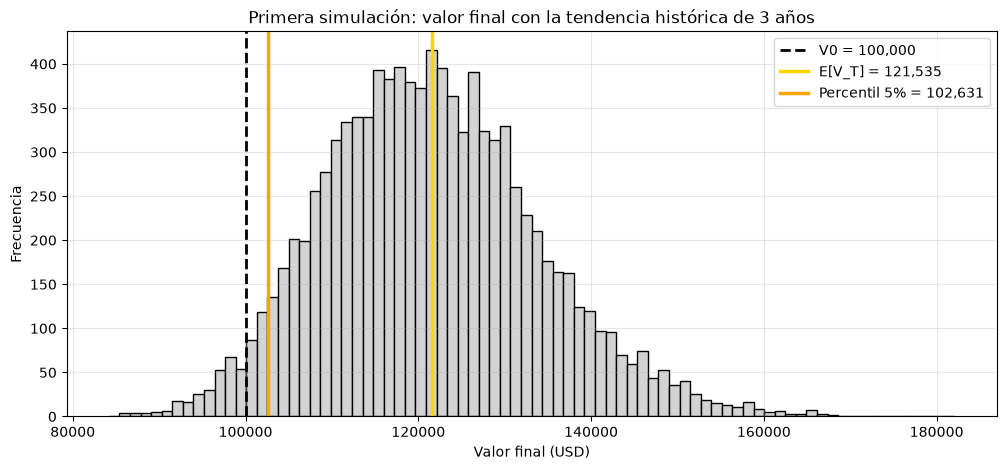

E[V_T]                      121535.45
Rendimiento esperado (%)        21.54
P(pérdida) (%)                   2.86
Percentil 5% de V_T         102630.59
VaR 95% (USD)                -2630.59
CVaR 95% (USD)                1551.26
dtype: float64

In [16]:
mu = mu_hist

np.random.seed(42)
eps = np.random.normal(0, 1, [M, k])
VT_hist = precios_finales(eps) @ N
VaR_hist, CVaR_hist = var_cvar(VT_hist)

fig, ax = plt.subplots(figsize=(12, 5))
ax.hist(VT_hist, bins=80, color="lightgray", edgecolor="black")
ax.axvline(V0, color="black", ls="--", lw=2, label=f"V0 = {V0:,.0f}")
ax.axvline(VT_hist.mean(), color="gold", lw=2.5, label=f"E[V_T] = {VT_hist.mean():,.0f}")
ax.axvline(V0 - VaR_hist, color="orange", lw=2.5,
           label=f"Percentil 5% = {V0 - VaR_hist:,.0f}")
ax.set_title("Primera simulación: valor final con la tendencia histórica de 3 años")
ax.set_xlabel("Valor final (USD)")
ax.set_ylabel("Frecuencia")
ax.legend()
plt.show()

pd.Series({"E[V_T]": VT_hist.mean(),
           "Rendimiento esperado (%)": (VT_hist.mean() / V0 - 1) * 100,
           "P(pérdida) (%)": (VT_hist < V0).mean() * 100,
           "Percentil 5% de V_T": V0 - VaR_hist,
           "VaR 95% (USD)": VaR_hist,
           "CVaR 95% (USD)": CVaR_hist}).round(2)

### ¿Qué observamos? ¿Por qué no usamos esta tendencia?

- **El modelo espera que el portafolio suba 21.5% en un año** ($E[V_T] = 121{,}535$ USD) y la probabilidad de perder dinero es de solo 2.9%.
- **El VaR al 95% sale negativo (-2,631 USD).** El percentil 5% del valor final es 102,631 USD: incluso en el 5% de peores escenarios el portafolio **gana** dinero. El CVaR, de apenas 1,551 USD, dice que en promedio el peor 5% casi no pierde.
- El histograma lo deja claro: casi toda la distribución queda a la derecha de $V_0$.

**¿Por qué no es un resultado confiable?**

1. **Extrapola un periodo excepcional.** El portafolio rindió 17.7% anual en tres años en los que el S&P 500 rindió 15.5%. Suponer que eso se repite es suponer que el próximo año será igual de bueno.
2. **Las medias históricas son muy imprecisas.** Con 3 años de datos, el error estándar del rendimiento promedio de cada activo es de 7 a 15 puntos porcentuales (se muestra en la siguiente tabla). Por ejemplo, el rendimiento de 26% de JPM es estadísticamente compatible con cualquier valor entre 0% y 53%.
3. **El VaR mezcla tendencia y riesgo.** Como vimos en la actividad de VaR, una tendencia alta empuja toda la distribución a la derecha y hace que el VaR parezca pequeño aunque el riesgo sea el mismo. Aquí el efecto es tan fuerte que el VaR cambia de signo.

Por estas razones, la simulación base del proyecto usa una tendencia más conservadora y mejor fundamentada.

### Ajuste de la tendencia con CAPM

En lugar de suponer que el próximo año se repetirán los últimos tres, el rendimiento esperado de cada activo se estima con el **modelo de valuación de activos de capital (CAPM)**:

$$E[R_i] = r_f + \beta_i \left(E[R_m] - r_f\right)$$

- $r_f$: tasa libre de riesgo, igual al rendimiento más reciente de los T-bills a 13 semanas (`^IRX`).
- $E[R_m] - r_f$: prima de riesgo de mercado. Se supone de **5%**, un valor de largo plazo dentro del rango que suele usarse en la práctica (entre 4% y 6%).
- $\beta_i$: la beta de cada activo contra el S&P 500, estimada en la sección 2.

**Por qué CAPM:**

1. **Solo se premia el riesgo que no se puede diversificar.** Según CAPM, un activo rinde más que la tasa libre de riesgo en proporción a su beta, no a su volatilidad total. Un activo como JNJ, que casi no se mueve con el mercado, no debería esperar un premio grande aunque haya subido mucho en los últimos años.
2. **La beta se estima con mucha más precisión que la media.** El error estándar de un rendimiento promedio de 3 años es $\sigma_i / \sqrt{3}$, que para estos activos va de 7 a 15 puntos porcentuales. La tabla lo muestra junto a cada estimación.
3. **No extrapola un periodo excepcional.** El rendimiento esperado deja de depender de qué tan bueno fue el pasado reciente.

Para que el modelo sea consistente, la tendencia del precio se fija en $\mu_i = \ln(1 + E[R_i])$, de modo que $E[S_i(T)] / S_i(0) = 1 + E[R_i]$.

In [17]:
data_rf = yf.download(["^IRX"], start="2026-10-01", end="2026-11-24",
                      auto_adjust=True, progress=False)
rf = data_rf["Close"]["^IRX"].dropna().iloc[-1] / 100      # tasa de T-bills a 13 semanas

prima_mercado = 0.05
rend_capm = rf + betas.loc[tickers, "Beta"] * prima_mercado

anios = len(log_ret) / 252
comparacion_mu = pd.DataFrame({
    "Beta": betas.loc[tickers, "Beta"],
    "Rend. esperado histórico (%)": (np.exp(mu_hist) - 1) * 100,
    "Error estándar del histórico (pp)": sigma / np.sqrt(anios) * 100,
    "Rend. esperado CAPM (%)": rend_capm * 100,
})

mu = np.log(1 + rend_capm)                 # así E[S_T] / S0 = 1 + rendimiento CAPM
mu_log = mu - 0.5 * sigma**2

print(f"Tasa libre de riesgo (T-bill 13 semanas): {rf * 100:.2f}%")
print(f"Prima de riesgo de mercado (supuesto):    {prima_mercado * 100:.2f}%")
print(f"Años de datos: {anios:.2f}")
comparacion_mu.round(2)

Tasa libre de riesgo (T-bill 13 semanas): 4.15%
Prima de riesgo de mercado (supuesto):    5.00%
Años de datos: 2.98


,Beta,Rend. esperado histórico (%),Error estándar del histórico (pp),Rend. esperado CAPM (%)
MSFT,0.98,14.12,15.33,9.04
JPM,0.88,33.89,13.62,8.53
JNJ,0.01,26.54,10.90,4.19
COST,0.37,27.37,11.90,6.00
XOM,0.14,21.68,13.70,4.85
GLD,0.33,24.77,12.95,5.80
TLT,0.08,1.94,7.26,4.55


### ¿Qué observamos?

- **La tasa libre de riesgo es de 4.15%** y, con la prima de 5%, el rendimiento esperado de cada activo queda entre 4.2% (JNJ) y 9.0% (MSFT).
- **El cambio respecto al histórico es enorme.** JPM pasa de 33.9% a 8.5%, JNJ de 26.5% a 4.2% y COST de 27.4% a 6.0%. Con CAPM, JNJ queda prácticamente en la tasa libre de riesgo porque su beta es casi cero: su subida de los últimos años no se explica por riesgo de mercado.
- **El orden también cambia.** MSFT, que fue de los que menos rindieron, ahora es el de mayor rendimiento esperado, porque es el de mayor beta. CAPM paga por el riesgo que se asume, no por el desempeño pasado.
- **La columna de error estándar justifica el cambio:** en seis de los siete activos la diferencia entre el histórico y CAPM es menor a 2 errores estándar de la media histórica, y en JNJ apenas lo rebasa. Los datos no permiten descartar que el rendimiento esperado real sea el de CAPM.

El rendimiento esperado del portafolio queda en 6.14% (el promedio de los siete valores CAPM), es decir, unos 2 puntos porcentuales sobre la tasa libre de riesgo. Es una prima modesta, consistente con una beta de portafolio de 0.42.

### Simulación base: M = 10,000 escenarios a T = 1 año (tendencia CAPM)

A partir de aquí todo el proyecto usa la tendencia CAPM. Se usan los mismos choques $\varepsilon$ (semilla 42) que en la primera simulación, así que la única diferencia es la tendencia.

In [18]:
np.random.seed(42)
eps = np.random.normal(0, 1, [M, k])

ST = precios_finales(eps)
VT = ST @ N
R  = VT / V0 - 1

corr_sim = pd.DataFrame(np.log(ST / S0.values), columns=tickers).corr()
print(f"Diferencia máxima entre la correlación simulada y la histórica: "
      f"{(corr_sim - correlacion.loc[tickers, tickers]).abs().values.max():.4f}")

pd.DataFrame({"S0": S0, "Media S_T simulada": ST.mean(axis=0),
              "E[S_T] teórico": S0.values * np.exp(mu.values * T)}).round(2)

Diferencia máxima entre la correlación simulada y la histórica: 0.0153


,S0,Media S_T simulada,E[S_T] teórico
Ticker,,,
MSFT,492.50,536.96,537.04
JPM,316.66,344.35,343.68
JNJ,268.71,280.62,279.98
COST,1067.91,1130.46,1132.00
XOM,156.90,164.11,164.52
GLD,333.02,352.93,352.34
TLT,81.69,85.54,85.40


### ¿Qué observamos?

La correlación simulada difiere de la histórica en como mucho 0.015, así que Cholesky reproduce bien la estructura de dependencia. Los precios promedio simulados coinciden con $S_i(0)\,(1 + E[R_i])$ dentro del ruido de simulación.

### Valor esperado y métricas de riesgo del portafolio

In [19]:
E_VT_exacto = V0 * np.sum(w * np.exp(mu.values * T))
se_base = VT.std(ddof=1) / np.sqrt(M)
VaR_base, CVaR_base = var_cvar(VT)

resumen_base = pd.Series({
    "E[V_T] simulado": VT.mean(),
    "E[V_T] teórico": E_VT_exacto,
    "IC 95% inferior": VT.mean() - 1.96 * se_base,
    "IC 95% superior": VT.mean() + 1.96 * se_base,
    "Mediana de V_T": np.median(VT),
    "Rendimiento esperado (%)": R.mean() * 100,
    "Volatilidad del rendimiento (%)": R.std() * 100,
    "P(pérdida) (%)": (VT < V0).mean() * 100,
    "VaR 95% (USD)": VaR_base,
    "CVaR 95% (USD)": CVaR_base,
})
resumen_base.round(2)

E[V_T] simulado                    106193.52
E[V_T] teórico                     106139.47
IC 95% inferior                    105984.52
IC 95% superior                    106402.51
Mediana de V_T                     105659.19
Rendimiento esperado (%)                6.19
Volatilidad del rendimiento (%)        10.66
P(pérdida) (%)                         29.18
VaR 95% (USD)                       10108.11
CVaR 95% (USD)                      13701.44
dtype: float64

### ¿Qué observamos?

- **Valor esperado del portafolio: 106,194 USD** con la simulación, contra 106,139 USD de la fórmula exacta. El valor exacto cae dentro del intervalo de confianza al 95% (105,985 a 106,403), como debe ser. Es un rendimiento esperado de alrededor de 6.2%.
- **La mediana (105,659) es menor que la media:** la distribución tiene una cola derecha más larga, propia de la lognormal.
- **Hay 29.2% de probabilidad de terminar el año con pérdida.** Un año de cada tres o cuatro, el portafolio vale menos que al inicio.
- **VaR 95% = 10,108 USD:** con 95% de confianza, en un año no se pierde más de 10.1% de la inversión.
- **CVaR 95% = 13,701 USD:** si cae en el 5% de peores escenarios, la pérdida promedio es de 13.7%.

Comparado con la primera simulación, la volatilidad y los choques son idénticos; solo cambió la tendencia. El VaR pasó de -2,631 a 10,108 USD: la diferencia de casi 12,700 USD se debe únicamente al optimismo de la tendencia histórica.

### Histograma de rendimientos

$$R = \frac{V_T}{V_0} - 1$$

Las barras rojas son el 5% de peores escenarios. La línea punteada es una normal con la misma media y desviación, como referencia.

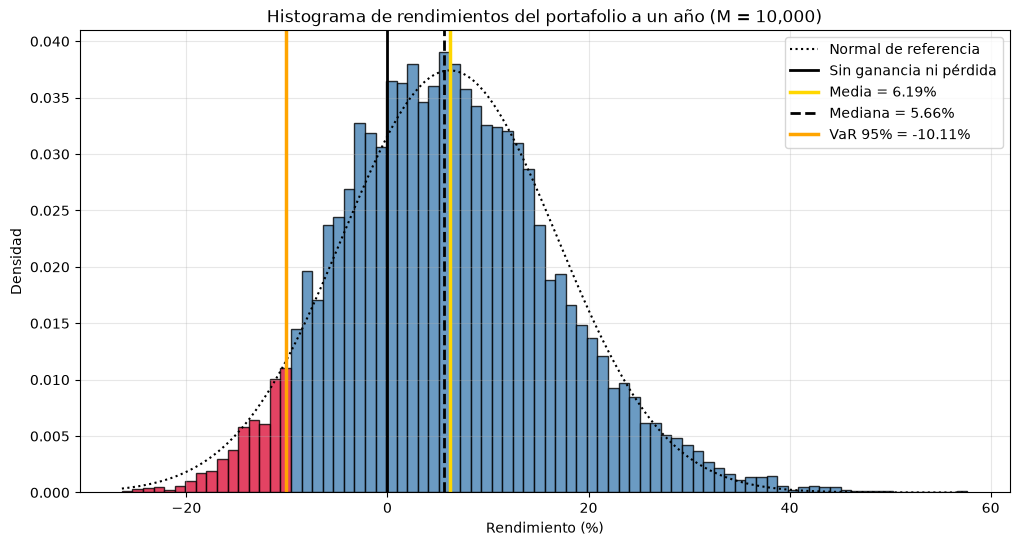

Asimetría de los rendimientos simulados: 0.359


In [20]:
R_pct = R * 100
x = np.linspace(R_pct.min(), R_pct.max(), 400)

fig, ax = plt.subplots(figsize=(12, 6))
n_barras, bins, barras = ax.hist(R_pct, bins=80, density=True, color="steelblue",
                                 edgecolor="black", alpha=0.8)
for barra, borde in zip(barras, bins[:-1]):
    if borde < -VaR_base / V0 * 100:
        barra.set_facecolor("crimson")

ax.plot(x, stats.norm.pdf(x, R_pct.mean(), R_pct.std()), color="black", lw=1.5,
        ls=":", label="Normal de referencia")
ax.axvline(0, color="black", lw=2, label="Sin ganancia ni pérdida")
ax.axvline(R_pct.mean(), color="gold", lw=2.5, label=f"Media = {R_pct.mean():.2f}%")
ax.axvline(np.median(R_pct), color="black", ls="--", lw=2,
           label=f"Mediana = {np.median(R_pct):.2f}%")
ax.axvline(-VaR_base / V0 * 100, color="orange", lw=2.5,
           label=f"VaR 95% = {-VaR_base / V0 * 100:.2f}%")
ax.set_title("Histograma de rendimientos del portafolio a un año (M = 10,000)")
ax.set_xlabel("Rendimiento (%)")
ax.set_ylabel("Densidad")
ax.legend(fontsize=10)
plt.show()

print(f"Asimetría de los rendimientos simulados: {stats.skew(R):.3f}")

### ¿Qué observamos?

- La media (6.19%) queda a la derecha de la mediana (5.66%) y la asimetría es positiva (0.36): las ganancias grandes llegan más lejos que las pérdidas grandes, porque un precio lognormal puede subir sin límite pero no puede caer más de 100%.
- La zona roja empieza en -10.1% (el VaR) y se extiende hasta cerca de -25%.
- **Ojo:** esta asimetría viene de la lognormal, no de los datos. En la sección 2 vimos que los rendimientos reales tienen colas pesadas en ambos lados, algo que esta distribución no reproduce. Las pérdidas extremas reales pueden ser más frecuentes de lo que sugiere la zona roja.

### Histograma de valores finales

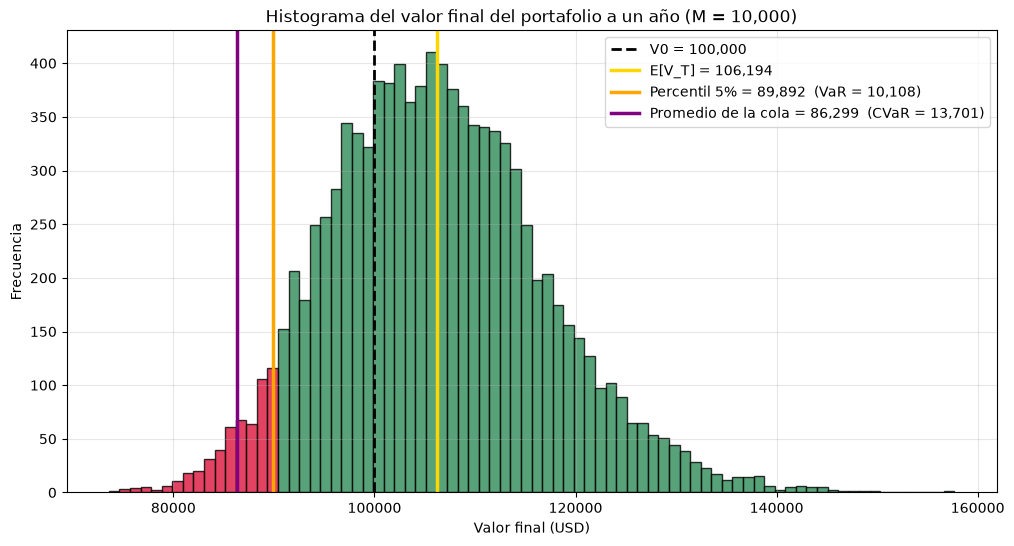

In [21]:
fig, ax = plt.subplots(figsize=(12, 6))
n_barras, bins, barras = ax.hist(VT, bins=80, color="seagreen", edgecolor="black", alpha=0.8)
for barra, borde in zip(barras, bins[:-1]):
    if borde < V0 - VaR_base:
        barra.set_facecolor("crimson")

ax.axvline(V0, color="black", ls="--", lw=2, label=f"V0 = {V0:,.0f}")
ax.axvline(VT.mean(), color="gold", lw=2.5, label=f"E[V_T] = {VT.mean():,.0f}")
ax.axvline(V0 - VaR_base, color="orange", lw=2.5,
           label=f"Percentil 5% = {V0 - VaR_base:,.0f}  (VaR = {VaR_base:,.0f})")
ax.axvline(V0 - CVaR_base, color="purple", lw=2.5,
           label=f"Promedio de la cola = {V0 - CVaR_base:,.0f}  (CVaR = {CVaR_base:,.0f})")
ax.set_title("Histograma del valor final del portafolio a un año (M = 10,000)")
ax.set_xlabel("Valor final (USD)")
ax.set_ylabel("Frecuencia")
ax.legend(fontsize=10)
plt.show()

### ¿Qué observamos?

El 5% de peores escenarios termina con un valor de 89,892 USD o menos, y el promedio de esos escenarios es de 86,299 USD. La mayor parte de la distribución está por encima de $V_0$, con la mayor concentración de escenarios entre 100,000 y 110,000 USD.

### ¿De dónde viene el riesgo?

Pesos iguales no significa riesgo igual. Se mide la aportación de cada activo de dos formas:

- **Contribución a la varianza** (descomposición de Euler): $\dfrac{w_i\,(\Sigma w)_i}{w^T \Sigma\, w}$. Suma 100%.
- **Contribución al CVaR:** en el 5% de peores escenarios, cuánto perdió en promedio cada activo. Suma el CVaR total.

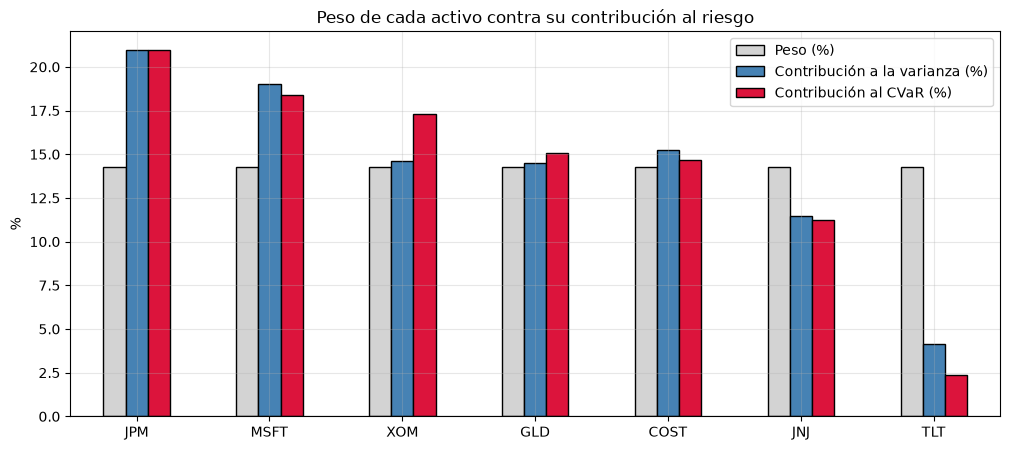

,Peso (%),Contribución a la varianza (%),Pérdida en la cola (USD),Contribución al CVaR (%)
JPM,14.29,20.95,2874.75,20.98
MSFT,14.29,19.02,2515.99,18.36
XOM,14.29,14.64,2369.63,17.29
GLD,14.29,14.50,2065.95,15.08
COST,14.29,15.26,2006.25,14.64
JNJ,14.29,11.46,1541.04,11.25
TLT,14.29,4.17,327.83,2.39


In [22]:
# Contribución a la varianza (descomposición de Euler)
contrib_var = w * (Sigma @ w) / (w @ Sigma @ w) * 100

# Contribución a la pérdida promedio en el 5% de peores escenarios (CVaR)
pnl_activos = (ST - S0.values) * N
cola = (VT - V0) <= -VaR_base
contrib_cvar = -pnl_activos[cola].mean(axis=0)

contribucion = pd.DataFrame({
    "Peso (%)": w * 100,
    "Contribución a la varianza (%)": contrib_var,
    "Pérdida en la cola (USD)": contrib_cvar,
    "Contribución al CVaR (%)": contrib_cvar / contrib_cvar.sum() * 100,
}, index=tickers).sort_values("Contribución al CVaR (%)", ascending=False)

ax = contribucion[["Peso (%)", "Contribución a la varianza (%)", "Contribución al CVaR (%)"]] \
    .plot(kind="bar", figsize=(12, 5), rot=0, edgecolor="black",
          color=["lightgray", "steelblue", "crimson"])
ax.axhline(0, color="black", lw=0.8)
ax.set_ylabel("%")
ax.set_title("Peso de cada activo contra su contribución al riesgo")
plt.show()

contribucion.round(2)

### ¿Qué observamos?

- **JPM y MSFT son el principal origen del riesgo.** Con 28.6% del dinero, aportan el 40% de la varianza y el 39% del CVaR. Son los activos con mayor volatilidad y los únicos con beta cercana a 1, así que son los que más pierden cuando el portafolio cae.
- **TLT es el gran estabilizador.** Con el mismo 14.3% de peso, aporta solo 4.2% de la varianza y 2.4% de la pérdida en la cola, por su baja volatilidad y su correlación casi nula o negativa con los demás.
- **XOM aporta más a la cola (17.3%) que a la varianza (14.6%):** en los peores escenarios del portafolio pierde más de lo que su volatilidad sugiere.
- **Pesos iguales no significa riesgo igual.** Para que cada activo aportara lo mismo al riesgo habría que reducir JPM y MSFT y aumentar TLT, que es justo lo que hace la optimización de la sección 7.

---

# 4. Métodos de reducción de varianza

El estimador de Monte Carlo tiene un error estándar de $\sigma_{V}/\sqrt{M}$: para reducir el error a la mitad hay que cuadruplicar las simulaciones. Los métodos de reducción de varianza buscan **el mismo resultado con menos error usando el mismo número de simulaciones**.

| Método | Idea | Cómo se aplica al portafolio |
|---|---|---|
| **Variables antitéticas** | Cada choque $\varepsilon$ se usa también con signo contrario, $-\varepsilon$ | 5,000 vectores $\varepsilon$ y sus 5,000 antitéticos (10,000 escenarios en total) |
| **Variable de control** | Se corrige el estimador con una variable muy correlacionada cuya media se conoce | Portafolio geométrico $G = V_0 \exp\left(\sum_i w_i \ln \frac{S_i(T)}{S_i(0)}\right)$ |
| **Quasi Monte Carlo (Sobol)** | Se sustituyen los números pseudoaleatorios por una secuencia de baja discrepancia que cubre el espacio de forma más uniforme | 10,000 puntos de Sobol de dimensión 7, transformados a normales con $\Phi^{-1}$ |

### La variable de control: el portafolio geométrico

Es la misma idea del control de Kemna-Vorst que usamos para las opciones asiáticas: cambiar una suma (o promedio aritmético) por un promedio geométrico, que sí tiene distribución conocida. Como $\ln G$ es una suma de normales:

$$\ln \frac{G}{V_0} \sim N\left(\sum_i w_i \left(\mu_i - \tfrac{1}{2}\sigma_i^2\right)T,\;\; w^T \Sigma\, w\; T\right) \quad\Rightarrow\quad E[G] = V_0 \exp\left(\sum_i w_i \left(\mu_i - \tfrac{1}{2}\sigma_i^2\right)T + \tfrac{1}{2} w^T\Sigma\, w\, T\right)$$

El estimador corregido es $\hat{V}_{cv} = \bar{V}_T - b\,(\bar{G} - E[G])$, con $b = \dfrac{\text{Cov}(V_T, G)}{\text{Var}(G)}$.

**VaR y CVaR con variable de control.** La corrección anterior solo mejora la media. Para el VaR y el CVaR se usa la versión equivalente por pesos: a cada escenario se le asigna un peso $p_s$ tal que el promedio ponderado de $G$ sea exactamente $E[G]$:

$$p_s = \frac{1}{M} + \frac{(E[G] - \bar{G})(G_s - \bar{G})}{\sum_j (G_j - \bar{G})^2}$$

El promedio ponderado de $V_T$ con estos pesos es justo $\hat{V}_{cv}$, y los cuantiles ponderados dan el VaR y el CVaR corregidos.

### Cómo se comparan los métodos

1. **Valores de referencia:** $E[V_T]$ con su fórmula exacta; el VaR y el CVaR, que no tienen fórmula, con una simulación de 2,000,000 escenarios.
2. **Una corrida** de cada método con $M = 10{,}000$ y semilla 42.
3. **50 repeticiones** de cada método con semillas distintas. La desviación estándar de las 50 estimaciones es el **error estándar** del método, medido de la misma forma para los cuatro (Sobol no tiene fórmula de error porque sus puntos no son independientes; aleatorizarlo con *scrambling* es lo que permite medirlo así).

### Valores de referencia

In [23]:
np.random.seed(2026)
VT_ref = np.concatenate([precios_finales(np.random.normal(0, 1, [500_000, k])) @ N
                         for _ in range(4)])
VaR_ref, CVaR_ref = var_cvar(VT_ref)

pd.Series({"E[V_T] exacto (fórmula)": E_VT_exacto,
           "E[V_T] con 2,000,000 simulaciones": VT_ref.mean(),
           "VaR 95% de referencia": VaR_ref,
           "CVaR 95% de referencia": CVaR_ref}).round(2)

E[V_T] exacto (fórmula)              106139.47
E[V_T] con 2,000,000 simulaciones    106139.17
VaR 95% de referencia                 10204.70
CVaR 95% de referencia                13716.22
dtype: float64

### ¿Qué observamos?

Con 2,000,000 de simulaciones, la media difiere del valor exacto en solo 0.30 USD, así que el VaR (10,205 USD) y el CVaR (13,716 USD) de esta corrida se pueden usar como "valores verdaderos" para medir qué tan lejos queda cada método.

### Implementación de los cuatro métodos

In [24]:
# Media y varianza conocidas de la variable de control (portafolio geométrico)
E_G = V0 * np.exp(w @ mu_log.values * T + 0.5 * (w @ Sigma @ w) * T)


def monte_carlo(semilla, n=M):
    np.random.seed(semilla)
    eps = np.random.normal(0, 1, [n, k])
    VT = precios_finales(eps) @ N
    var, cvar = var_cvar(VT)
    return {"Valor estimado": VT.mean(), "VaR95": var, "CVaR95": cvar,
            "Error estándar (fórmula)": VT.std(ddof=1) / np.sqrt(n), "VT": VT}


def antiteticas(semilla, n=M):
    np.random.seed(semilla)
    eps_mitad = np.random.normal(0, 1, [n // 2, k])
    eps = np.vstack([eps_mitad, -eps_mitad])               # n/2 de ε y n/2 de -ε
    VT = precios_finales(eps) @ N
    pares = (VT[: n // 2] + VT[n // 2:]) / 2
    var, cvar = var_cvar(VT)
    return {"Valor estimado": VT.mean(), "VaR95": var, "CVaR95": cvar,
            "Error estándar (fórmula)": pares.std(ddof=1) / np.sqrt(n // 2), "VT": VT}


def variable_control(semilla, n=M):
    np.random.seed(semilla)
    eps = np.random.normal(0, 1, [n, k])
    ST = precios_finales(eps)
    VT = ST @ N
    G  = V0 * np.exp(np.log(ST / S0.values) @ w)          # portafolio geométrico
    b  = np.cov(VT, G)[0, 1] / G.var(ddof=1)
    VT_cv = VT - b * (G - E_G)
    # Pesos por escenario que hacen que el promedio ponderado de G sea exactamente E[G]
    pesos = 1 / n + (E_G - G.mean()) * (G - G.mean()) / np.sum((G - G.mean()) ** 2)
    var, cvar = var_cvar(VT, pesos=pesos)
    return {"Valor estimado": VT_cv.mean(), "VaR95": var, "CVaR95": cvar,
            "Error estándar (fórmula)": VT_cv.std(ddof=1) / np.sqrt(n), "VT": VT,
            "G": G, "b": b}


def sobol(semilla, n=M):
    sampler = qmc.Sobol(d=k, scramble=True, rng=np.random.default_rng(semilla))
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", UserWarning)       # n no es potencia de 2
        U = sampler.random(n)
    eps = stats.norm.ppf(U)
    VT = precios_finales(eps) @ N
    var, cvar = var_cvar(VT)
    return {"Valor estimado": VT.mean(), "VaR95": var, "CVaR95": cvar,
            "Error estándar (fórmula)": np.nan, "VT": VT}


metodos = {
    "Monte Carlo": monte_carlo,
    "Variables antitéticas": antiteticas,
    "Variable de control": variable_control,
    "Quasi Monte Carlo (Sobol)": sobol,
}

### Calidad de la variable de control

Una variable de control sirve en la medida en que esté correlacionada con lo que se quiere estimar: la varianza se reduce por un factor $1/(1-\rho^2)$.

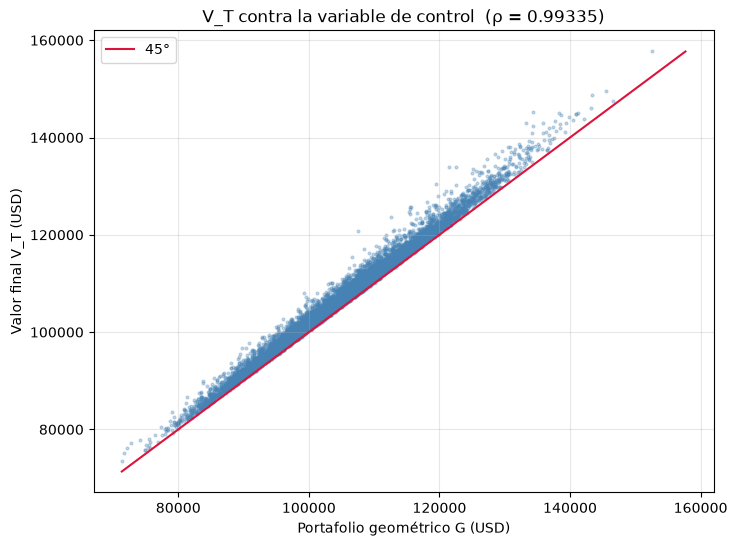

E[G] exacto: 104,195.05   Promedio simulado de G: 104,252.84
Coeficiente óptimo b: 1.0247
Reducción teórica de varianza: 1 / (1 - ρ²) = 75.4 veces


In [25]:
cv = variable_control(42)
rho_vg = np.corrcoef(cv["VT"], cv["G"])[0, 1]

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(cv["G"], cv["VT"], s=4, alpha=0.3, color="steelblue")
lim = [min(cv["G"].min(), cv["VT"].min()), max(cv["G"].max(), cv["VT"].max())]
ax.plot(lim, lim, color="crimson", lw=1.5, label="45°")
ax.set_xlabel("Portafolio geométrico G (USD)")
ax.set_ylabel("Valor final V_T (USD)")
ax.set_title(f"V_T contra la variable de control  (ρ = {rho_vg:.5f})")
ax.legend()
plt.show()

print(f"E[G] exacto: {E_G:,.2f}   Promedio simulado de G: {cv['G'].mean():,.2f}")
print(f"Coeficiente óptimo b: {cv['b']:.4f}")
print(f"Reducción teórica de varianza: 1 / (1 - ρ²) = {1 / (1 - rho_vg**2):,.1f} veces")

### ¿Qué observamos?

- **La correlación entre $V_T$ y $G$ es de 0.993:** los puntos forman prácticamente una línea. El portafolio geométrico siempre queda un poco abajo del aritmético (por la desigualdad de las medias), pero se mueve casi igual.
- **La reducción teórica de varianza es de 75 veces.**
- **Cómo corrige:** en esta corrida, el promedio simulado de $G$ quedó 57.8 USD **arriba** de su valor exacto. Como $V_T$ se mueve igual, su promedio también está inflado, y el estimador le resta $b \times 57.8 = 1.0247 \times 57.8 \approx 59$ USD. Por eso la estimación pasa de 106,194 a 106,134 USD, a solo 5 USD del valor exacto.

### Una corrida de cada método (M = 10,000, semilla 42)

In [26]:
corrida = {nombre: f(42) for nombre, f in metodos.items()}

tabla_unica = pd.DataFrame({nombre: {c: v for c, v in res.items()
                                     if c in ["Valor estimado", "VaR95", "CVaR95",
                                              "Error estándar (fórmula)"]}
                            for nombre, res in corrida.items()}).T
tabla_unica.loc["Referencia"] = [E_VT_exacto, VaR_ref, CVaR_ref, np.nan]
tabla_unica.round(2)

,Valor estimado,VaR95,CVaR95,Error estándar (fórmula)
Monte Carlo,106193.52,10108.11,13701.44,106.63
Variables antitéticas,106151.38,10119.99,13677.13,20.92
Variable de control,106134.30,10134.54,13744.28,12.28
Quasi Monte Carlo (Sobol),106141.38,9979.88,13694.39,NaN
Referencia,106139.47,10204.70,13716.22,NaN


### ¿Qué observamos?

Error de cada método respecto a los valores de referencia, en esta corrida:

| Método | Error en E[V_T] | Error en VaR | Error en CVaR |
|---|---|---|---|
| Monte Carlo | +54.1 | -96.6 | -14.8 |
| Antitéticas | +11.9 | -84.7 | -39.1 |
| Variable de control | -5.2 | -70.2 | +28.1 |
| Sobol | +1.9 | -224.8 | -21.8 |

- **Para el valor esperado, los tres métodos mejoran a Monte Carlo**, y Sobol queda a menos de 2 USD del valor exacto.
- **Para el VaR, una sola corrida no basta para comparar:** Sobol tuvo aquí el mayor error en el VaR (-225 USD). Con una sola semilla, la suerte pesa tanto como el método. Por eso la comparación seria se hace con 50 repeticiones.
- El error estándar por fórmula ya anticipa el resultado para la media: 107 USD con Monte Carlo, 21 con antitéticas y 12 con variable de control.

### 50 repeticiones de cada método

Para cada métrica se reporta el error estándar (desviación de las 50 estimaciones) y el **factor de reducción de varianza** respecto a Monte Carlo:

$$\text{Reducción} = \frac{\text{Var}(\text{estimador MC})}{\text{Var}(\text{estimador del método})}$$

Un factor de 10 significa que el método logra con 10,000 simulaciones la precisión que Monte Carlo lograría con 100,000.

In [27]:
R_rep = 50
estimaciones = {nombre: [] for nombre in metodos}
tiempos = {}

for nombre, f in metodos.items():
    inicio = time.perf_counter()
    for semilla in range(1, R_rep + 1):
        res = f(semilla)
        estimaciones[nombre].append([res["Valor estimado"], res["VaR95"], res["CVaR95"]])
    tiempos[nombre] = (time.perf_counter() - inicio) / R_rep * 1000
    estimaciones[nombre] = pd.DataFrame(estimaciones[nombre],
                                        columns=["Valor estimado", "VaR95", "CVaR95"])

referencia = {"Valor estimado": E_VT_exacto, "VaR95": VaR_ref, "CVaR95": CVaR_ref}
se_mc = estimaciones["Monte Carlo"].std()

filas = []
for nombre, est in estimaciones.items():
    se = est.std()
    fila = {"Método": nombre}
    for col in ["Valor estimado", "VaR95", "CVaR95"]:
        fila[f"Error estándar {col}"] = se[col]
        fila[f"Reducción de varianza {col}"] = (se_mc[col] / se[col]) ** 2
    fila["Tiempo por corrida (ms)"] = tiempos[nombre]
    filas.append(fila)

tabla_rep = pd.DataFrame(filas).set_index("Método")
tabla_rep.round(2).T

Método,Monte Carlo,Variables antitéticas,Variable de control,Quasi Monte Carlo (Sobol)
Error estándar Valor estimado,110.74,19.23,11.89,1.09
Reducción de varianza Valor estimado,1.00,33.15,86.70,10252.18
Error estándar VaR95,176.67,193.46,164.87,96.16
Reducción de varianza VaR95,1.00,0.83,1.15,3.38
Error estándar CVaR95,202.21,195.99,189.10,54.42
Reducción de varianza CVaR95,1.00,1.06,1.14,13.81
Tiempo por corrida (ms),3.11,1.60,2.95,3.44


### ¿Qué observamos?

**Valor esperado:**
- Antitéticas reduce la varianza 33 veces, variable de control 87 veces y Sobol **más de 10,000 veces**: su error estándar es de 1.09 USD contra 110.74 de Monte Carlo.
- Los errores estándar medidos con las repeticiones coinciden con los de la fórmula de la corrida única (21 contra 19 en antitéticas, 12 contra 12 en control), lo que confirma que las fórmulas están bien aplicadas.

**VaR y CVaR:**
- **Antitéticas y variable de control casi no ayudan.** Sus factores van de 0.83 a 1.15. En antitéticas el VaR incluso sale un poco peor (0.83), aunque con 50 repeticiones esa diferencia está dentro del ruido.
- **Sobol es el único que mejora las colas:** reduce la varianza del VaR 3.4 veces y la del CVaR 13.8 veces.

**Costo:**
- Todos los métodos tardan entre 1.5 y 3.9 milisegundos por corrida, así que la diferencia de costo es irrelevante aquí.
- Antitéticas es el más rápido, porque solo genera la mitad de los números aleatorios.

### Tabla comparativa de métodos

El valor estimado, el VaR y el CVaR vienen de la corrida con semilla 42. El error estándar es el del estimador de $E[V_T]$, medido con las 50 repeticiones.

In [28]:
tabla_metodos = pd.DataFrame({
    "Valor estimado": tabla_unica["Valor estimado"],
    "VaR95": tabla_unica["VaR95"],
    "CVaR95": tabla_unica["CVaR95"],
    "Error estándar": tabla_rep["Error estándar Valor estimado"],
}).loc[list(metodos.keys())]

tabla_metodos.index = ["Monte Carlo", "Variables antitéticas", "Variable de control",
                       "Quasi Monte Carlo"]
tabla_metodos.index.name = "Método"
tabla_metodos.round(2)

,Valor estimado,VaR95,CVaR95,Error estándar
Método,,,,
Monte Carlo,106193.52,10108.11,13701.44,110.74
Variables antitéticas,106151.38,10119.99,13677.13,19.23
Variable de control,106134.30,10134.54,13744.28,11.89
Quasi Monte Carlo,106141.38,9979.88,13694.39,1.09


### ¿Qué observamos?

Los cuatro métodos dan prácticamente el mismo valor esperado (entre 106,134 y 106,194 USD) y valores de VaR y CVaR parecidos. Donde se separan es en el error estándar: de 110.74 USD con Monte Carlo a 1.09 USD con Quasi Monte Carlo. El valor exacto es 106,139.47 USD.

### Dispersión de las 50 estimaciones de cada método

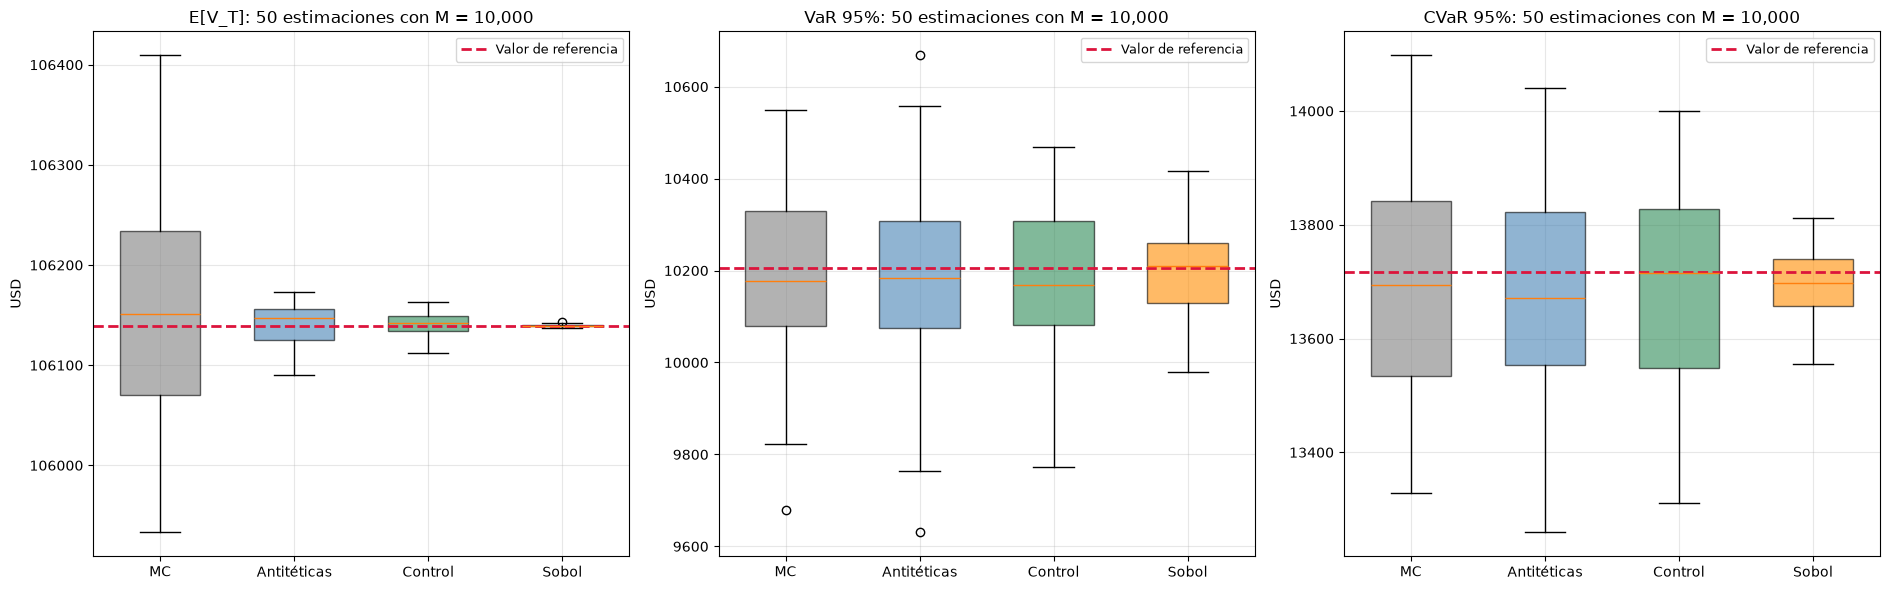

In [29]:
fig, axes = plt.subplots(1, 3, figsize=(19, 6))
nombres_cortos = ["MC", "Antitéticas", "Control", "Sobol"]
colores_m = ["gray", "steelblue", "seagreen", "darkorange"]

for ax, col, titulo in zip(axes, ["Valor estimado", "VaR95", "CVaR95"],
                           ["E[V_T]", "VaR 95%", "CVaR 95%"]):
    datos = [estimaciones[nombre][col] for nombre in metodos]
    caja = ax.boxplot(datos, tick_labels=nombres_cortos, patch_artist=True, widths=0.6)
    for parche, color in zip(caja["boxes"], colores_m):
        parche.set_facecolor(color); parche.set_alpha(0.6)
    ax.axhline(referencia[col], color="crimson", ls="--", lw=2, label="Valor de referencia")
    ax.set_title(f"{titulo}: {R_rep} estimaciones con M = 10,000")
    ax.set_ylabel("USD")
    ax.legend(fontsize=9)

plt.tight_layout()
plt.show()

### ¿Qué observamos?

- **En el valor esperado**, la caja de Sobol es apenas una línea sobre el valor de referencia; las de control y antitéticas son mucho más angostas que la de Monte Carlo.
- **En el VaR**, Monte Carlo, antitéticas y control tienen prácticamente la misma dispersión (de 9,600 a 10,700 USD). Solo Sobol es claramente más angosto.
- **En el CVaR**, Sobol vuelve a destacar: sus 50 estimaciones van de 13,560 a 13,810 USD, mientras que las de los otros tres métodos cubren entre 700 y 800 USD.
- **Ningún método tiene sesgo:** todas las cajas están centradas en el valor de referencia.

### Factor de reducción de varianza

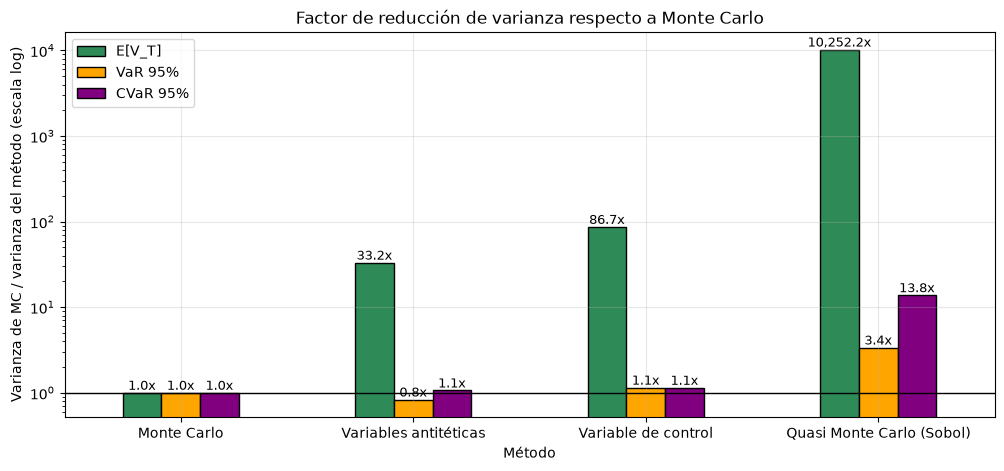

In [30]:
reduccion = tabla_rep[[f"Reducción de varianza {c}" for c in ["Valor estimado", "VaR95", "CVaR95"]]]
reduccion.columns = ["E[V_T]", "VaR 95%", "CVaR 95%"]

ax = reduccion.plot(kind="bar", figsize=(12, 5), rot=0, edgecolor="black", logy=True,
                    color=["seagreen", "orange", "purple"])
for barras in ax.containers:
    ax.bar_label(barras, fmt="{:,.1f}x", fontsize=9)
ax.axhline(1, color="black", lw=1)
ax.set_ylabel("Varianza de MC / varianza del método (escala log)")
ax.set_title("Factor de reducción de varianza respecto a Monte Carlo")
plt.show()

### ¿Qué observamos?

La gráfica (en escala logarítmica) resume la comparación: la ventaja de antitéticas y variable de control está **solo en la media**, mientras que Sobol domina en las tres métricas. Para un proyecto cuyo objetivo es medir el riesgo, lo que más importa es la precisión del VaR y del CVaR, no solo de la media.

### Convergencia: error contra número de simulaciones

Se repite cada método 30 veces para tamaños de 256 a 16,384 simulaciones (potencias de 2, donde Sobol tiene su mejor balance) y se mide el error cuadrático medio de $E[V_T]$. En escala log-log, Monte Carlo debe tener pendiente $-1/2$; un método que converge más rápido tiene una pendiente más negativa.

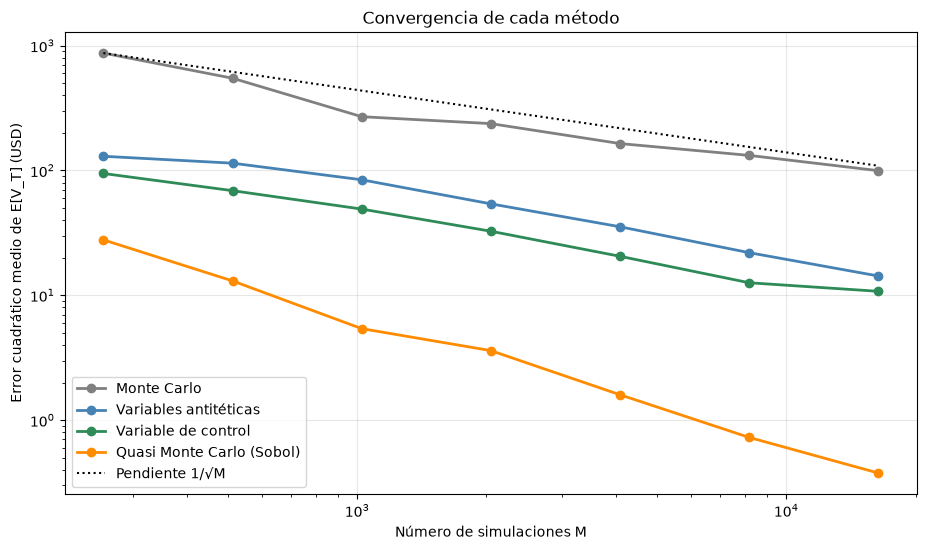

Monte Carlo                 -0.508
Variables antitéticas       -0.556
Variable de control         -0.556
Quasi Monte Carlo (Sobol)   -1.025
Name: Pendiente log-log (MC teórico = -0.5), dtype: float64

In [31]:
tamanos = [2**j for j in range(8, 15)]          # de 256 a 16,384 simulaciones
rep_conv = 30
rmse = {nombre: [] for nombre in metodos}

for n in tamanos:
    for nombre, f in metodos.items():
        errores = [f(semilla, n)["Valor estimado"] - E_VT_exacto
                   for semilla in range(100, 100 + rep_conv)]
        rmse[nombre].append(np.sqrt(np.mean(np.square(errores))))

fig, ax = plt.subplots(figsize=(11, 6))
for (nombre, valores), color in zip(rmse.items(), colores_m):
    ax.loglog(tamanos, valores, "o-", color=color, lw=2, label=nombre)
ref = rmse["Monte Carlo"][0] * np.sqrt(tamanos[0] / np.array(tamanos))
ax.loglog(tamanos, ref, color="black", ls=":", label="Pendiente 1/√M")
ax.set_xlabel("Número de simulaciones M")
ax.set_ylabel("Error cuadrático medio de E[V_T] (USD)")
ax.set_title("Convergencia de cada método")
ax.legend()
plt.show()

pendientes = {nombre: np.polyfit(np.log(tamanos), np.log(v), 1)[0] for nombre, v in rmse.items()}
pd.Series(pendientes, name="Pendiente log-log (MC teórico = -0.5)").round(3)

### ¿Qué observamos?

- **Monte Carlo, antitéticas y variable de control tienen pendiente cercana a $-1/2$** (-0.51, -0.56 y -0.56): reducen el error de forma proporcional, pero no cambian la velocidad de convergencia. Su ventaja es un desplazamiento hacia abajo de la línea.
- **Sobol tiene pendiente de -1.03**, es decir, su error decrece como $1/M$ y no como $1/\sqrt{M}$. Duplicar las simulaciones reduce su error a la mitad, mientras que en Monte Carlo solo lo reduce 29%. Por eso la ventaja de Sobol crece conforme aumenta $M$.
- Con 256 simulaciones, Sobol ya tiene menos error (28 USD) que Monte Carlo con 16,384 (99 USD).

### Ventajas, desventajas y método recomendado

| Método | Ventajas observadas | Desventajas observadas |
|---|---|---|
| **Variables antitéticas** | Fácil de implementar; reduce 33 veces la varianza de la media; es el más rápido, porque genera la mitad de los números aleatorios | No mejora el VaR ni el CVaR: la simetría $\varepsilon, -\varepsilon$ ayuda a la media, pero no a los cuantiles de la cola |
| **Variable de control** | Reduce 87 veces la varianza de la media; da un error estándar con una sola corrida | Requiere una variable con media conocida (aquí, la fórmula del portafolio geométrico); para el VaR y el CVaR hay que reponderar escenarios y la mejora es mínima (1.15 veces) |
| **Quasi Monte Carlo (Sobol)** | Reduce más de 10,000 veces la varianza de la media, 3.4 veces la del VaR y 13.8 veces la del CVaR; converge como $1/M$; casi no cuesta más | No da error estándar con una sola corrida (hay que aleatorizarlo y repetir); pierde balance si $M$ no es potencia de 2; su ventaja se reduce en dimensiones altas; una sola corrida todavía puede desviarse en el VaR |

**Método recomendado: Quasi Monte Carlo con Sobol aleatorizado (*scrambled*).**

Es el único que mejora las tres cantidades que importan en este proyecto, en especial el VaR y el CVaR, que son el objetivo del análisis de riesgo. Su principal desventaja (no tener error estándar en una sola corrida) se resuelve con unas cuantas repeticiones aleatorizadas, y su otra limitación (la dimensión) no es un problema aquí: el portafolio solo necesita 7 números aleatorios por escenario. Si el modelo se extendiera a trayectorias diarias (7 × 252 = 1,764 dimensiones), la ventaja de Sobol se reduciría y la variable de control sería una buena alternativa para la media.

Como recomendación práctica, conviene usar $M$ en potencias de 2 (por ejemplo, $2^{14} = 16{,}384$).

---

# 5. Pruebas de estrés

El VaR y el CVaR de la sección 3 miden el riesgo **dentro** del modelo calibrado con los últimos tres años. Las pruebas de estrés revisan qué pasa cuando las condiciones cambian de forma extrema.

| Escenario | Choque | ¿Se vuelve a simular? |
|---|---|---|
| 1. Caída general del mercado | El S&P 500 cae 35% y cada activo cae según su beta: $\text{choque}_i = \beta_i \times (-35\%)$ | No |
| 2. Doble volatilidad | $\sigma_i \times 2$ para todos los activos, es decir, $\Sigma \times 4$ | Sí |
| 3. Colapso de diversificación | $\rho_{ij} = 1$ entre todos los activos | Sí |
| 4. COVID 2020 (histórico) | Cada activo recibe la caída real que tuvo entre el 19 de febrero y el 23 de marzo de 2020 | No |

En todos los escenarios se usan los mismos $\varepsilon$ de la simulación base, para que las diferencias se deban solo al choque.

In [32]:
def resumen_escenario(VT):
    var, cvar = var_cvar(VT)
    return {"E[V_T]": VT.mean(), "P(pérdida) (%)": (VT < V0).mean() * 100,
            "VaR95": var, "CVaR95": cvar, "Peor pérdida": V0 - VT.min()}

## Escenario 1. Caída general del mercado

Una caída de 35% del S&P 500 es comparable con la del COVID en 2020 (alrededor de 34%). En lugar de bajar todos los activos por igual, cada uno cae en proporción a su beta: los activos más ligados al mercado caen más, y los que tienen beta cercana a cero (o negativa) casi no se mueven. El choque se aplica sobre los precios finales ya simulados:

$$S_i^{\text{estrés}}(T) = S_i(T)\,(1 + \beta_i \times (-35\%))$$

In [33]:
caida_mercado = -0.35
choque_1 = np.clip(betas.loc[tickers, "Beta"].values * caida_mercado, -0.95, None)

ST_1 = ST * (1 + choque_1)
VT_1 = ST_1 @ N

pd.DataFrame({"Beta": betas.loc[tickers, "Beta"], "Choque al precio (%)": choque_1 * 100},
             index=tickers).round(2)

,Beta,Choque al precio (%)
MSFT,0.98,-34.27
JPM,0.88,-30.71
JNJ,0.01,-0.33
COST,0.37,-12.98
XOM,0.14,-4.96
GLD,0.33,-11.58
TLT,0.08,-2.80


### ¿Qué observamos?

- **MSFT y JPM reciben casi todo el golpe** (-34% y -31%), porque su beta es cercana a 1. JNJ, XOM y TLT casi no se mueven (menos de 5%).
- En promedio, los activos caen 14%, muy cerca de lo que predice la beta del portafolio ($0.42 \times 35\% \approx 15\%$).
- **Este escenario depende de que la beta se mantenga en una crisis**, y el escenario 4 muestra que eso no siempre pasa.

## Escenario 2. Doble volatilidad

Si cada $\sigma_i$ se duplica, cada covarianza se multiplica por 4, porque $\text{Cov}_{ij} = \rho_{ij}\,\sigma_i\,\sigma_j$. La correlación no cambia. El término $-\tfrac{1}{2}\Sigma_{ii}$ se recalcula con la nueva varianza, así que el valor esperado de cada precio se mantiene, pero la distribución se abre.

In [34]:
Sigma_2 = 4 * Sigma
L_2 = np.linalg.cholesky(Sigma_2)

ST_2 = precios_finales(eps, L_2, Sigma_2)
VT_2 = ST_2 @ N

pd.DataFrame({"sigma base (%)": sigma * 100,
              "sigma estresada (%)": np.sqrt(np.diag(Sigma_2)) * 100}, index=tickers).round(2)

,sigma base (%),sigma estresada (%)
MSFT,26.46,52.92
JPM,23.50,47.01
JNJ,18.81,37.62
COST,20.54,41.07
XOM,23.66,47.32
GLD,22.35,44.70
TLT,12.53,25.05


## Escenario 3. Colapso de diversificación (ρ = 1)

Con $\rho_{ij} = 1$, la matriz de correlación es una matriz de puros unos. Sus eigenvalores son $7, 0, 0, 0, 0, 0, 0$: no es definida positiva, y Cholesky falla.

In [35]:
Sigma_3 = np.outer(sigma, sigma)          # ρ = 1 para todos los pares

print("Eigenvalores de la matriz de correlación con ρ = 1:")
print(np.linalg.eigvalsh(np.ones((k, k))).round(6))
try:
    np.linalg.cholesky(Sigma_3)
    print("\nCholesky funcionó")
except np.linalg.LinAlgError as error:
    print(f"\nCholesky falla: {error}")

Eigenvalores de la matriz de correlación con ρ = 1:
[-0. -0. -0.  0.  0.  0.  7.]

Cholesky falla: Matrix is not positive definite


Si todos los activos se mueven exactamente igual, basta un solo choque por escenario, escalado por la volatilidad de cada activo: $Z_i = \sigma_i\,\varepsilon_1$. En forma matricial, $L$ tiene las volatilidades en la primera columna y ceros en el resto, y sigue cumpliendo $L\,L^T = \Sigma$.

In [36]:
L_3 = np.zeros((k, k))
L_3[:, 0] = sigma                          # un solo choque para todos: Z_i = σ_i ε_1

print(f"¿L · Lᵀ reconstruye Σ? {np.allclose(L_3 @ L_3.T, Sigma_3)}")

ST_3 = precios_finales(eps, L_3, Sigma_3)
VT_3 = ST_3 @ N

¿L · Lᵀ reconstruye Σ? True


## Escenario 4. COVID 2020 (escenario histórico)

Se descargan los precios del 19 de febrero de 2020 (máximo del S&P 500 antes de la pandemia) al 23 de marzo de 2020 (mínimo), y cada activo recibe la caída que tuvo en realidad. A diferencia del escenario 1, aquí no se supone nada: los choques son los que ocurrieron.

In [37]:
data_covid = yf.download(tickers + [benchmark], start="2020-02-18", end="2020-03-25",
                         auto_adjust=True, progress=False)
precios_covid = data_covid["Close"][tickers + [benchmark]]

antes   = precios_covid.loc[:"2020-02-19"].iloc[-1]
despues = precios_covid.loc[:"2020-03-23"].iloc[-1]
choque_covid = despues / antes - 1

ST_4 = ST * (1 + choque_covid[tickers].values)
VT_4 = ST_4 @ N

comparacion_choques = pd.DataFrame({
    "Choque COVID real (%)": choque_covid[tickers] * 100,
    "Choque por beta, escenario 1 (%)": choque_1 * 100,
})
print(f"Caída real del S&P 500 entre el 19 de febrero y el 23 de marzo de 2020: "
      f"{choque_covid[benchmark] * 100:.2f}%")
comparacion_choques.round(2)

Caída real del S&P 500 entre el 19 de febrero y el 23 de marzo de 2020: -33.92%


,Choque COVID real (%),"Choque por beta, escenario 1 (%)"
Ticker,,
MSFT,-27.39,-34.27
JPM,-42.52,-30.71
JNJ,-24.90,-0.33
COST,-11.61,-12.98
XOM,-47.88,-4.96
GLD,-3.62,-11.58
TLT,14.23,-2.80


### ¿Qué observamos?

- **En el COVID el S&P 500 cayó 33.9%**, casi lo mismo que el escenario 1, pero los choques de cada activo fueron muy distintos a los que predice la beta:
  - **JNJ cayó 24.9%** (la beta predecía 0.3%) y **XOM 47.9%** (la beta predecía 5%). En la crisis, activos que normalmente no se mueven con el mercado cayeron con todo lo demás: la beta "de tiempos normales" subestima la caída.
  - **TLT subió 14.2%:** los bonos del Tesoro funcionaron como refugio. Es el único activo que compensó pérdidas.
  - **GLD solo cayó 3.6%**, menos de lo que predecía su beta.
- En promedio los activos cayeron 20.5%, contra 14% del escenario por beta. Es como si la beta del portafolio hubiera subido de 0.42 a cerca de 0.6.

Es la confirmación práctica de lo que vimos en la correlación móvil: **en las crisis las correlaciones suben y la diversificación protege menos.**

### Tabla completa de escenarios

In [38]:
escenarios = {
    "Base": VT,
    "1. Caída general del mercado": VT_1,
    "2. Doble volatilidad": VT_2,
    "3. Colapso de diversificación": VT_3,
    "4. COVID 2020 (histórico)": VT_4,
}

tabla_stress = pd.DataFrame({nombre: resumen_escenario(v) for nombre, v in escenarios.items()}).T
tabla_stress["VaR vs base (veces)"] = tabla_stress["VaR95"] / tabla_stress.loc["Base", "VaR95"]
tabla_stress.index.name = "Escenario"
tabla_stress.round(2)

,E[V_T],P(pérdida) (%),VaR95,CVaR95,Peor pérdida,VaR vs base (veces)
Escenario,,,,,,
Base,106193.52,29.18,10108.11,13701.44,26414.22,1.00
1. Caída general del mercado,91159.53,84.71,22443.31,25387.67,35538.00,2.22
2. Doble volatilidad,106244.73,42.76,24870.06,30532.55,47534.89,2.46
3. Colapso de diversificación,106135.26,42.51,26463.27,32630.01,56244.35,2.62
4. COVID 2020 (histórico),84278.58,96.41,28048.65,30825.92,42687.60,2.77


### ¿Qué observamos?

- **Caída general del mercado:** el valor esperado baja a 91,160 USD y la probabilidad de pérdida sube de 29% a 85%. El VaR se duplica (22,443 USD).
- **Doble volatilidad:** el valor esperado no cambia (106,245 USD), porque el término $-\tfrac{1}{2}\Sigma_{ii}$ lo protege, pero la distribución se abre: el VaR sube 2.5 veces (24,870 USD) y la peor pérdida llega a 47,535 USD.
- **Colapso de diversificación:** sin cambiar la volatilidad de ningún activo, solo por hacer que todos se muevan igual, el VaR sube 2.6 veces (26,463 USD) y se tiene la **peor pérdida de todos los escenarios: 56,244 USD**.
- **COVID 2020:** es el escenario con el **mayor VaR (28,049 USD, 2.8 veces el base)** y una probabilidad de pérdida de 96%: prácticamente en todos los escenarios se pierde dinero.

En los cuatro escenarios, el VaR al 95% queda entre 2.2 y 2.8 veces el del escenario base.

### Tabla de VaR y CVaR por escenario

In [39]:
tabla_stress[["VaR95", "CVaR95"]].round(2)

,VaR95,CVaR95
Escenario,,
Base,10108.11,13701.44
1. Caída general del mercado,22443.31,25387.67
2. Doble volatilidad,24870.06,30532.55
3. Colapso de diversificación,26463.27,32630.01
4. COVID 2020 (histórico),28048.65,30825.92


### Escenario base vs cada escenario de estrés

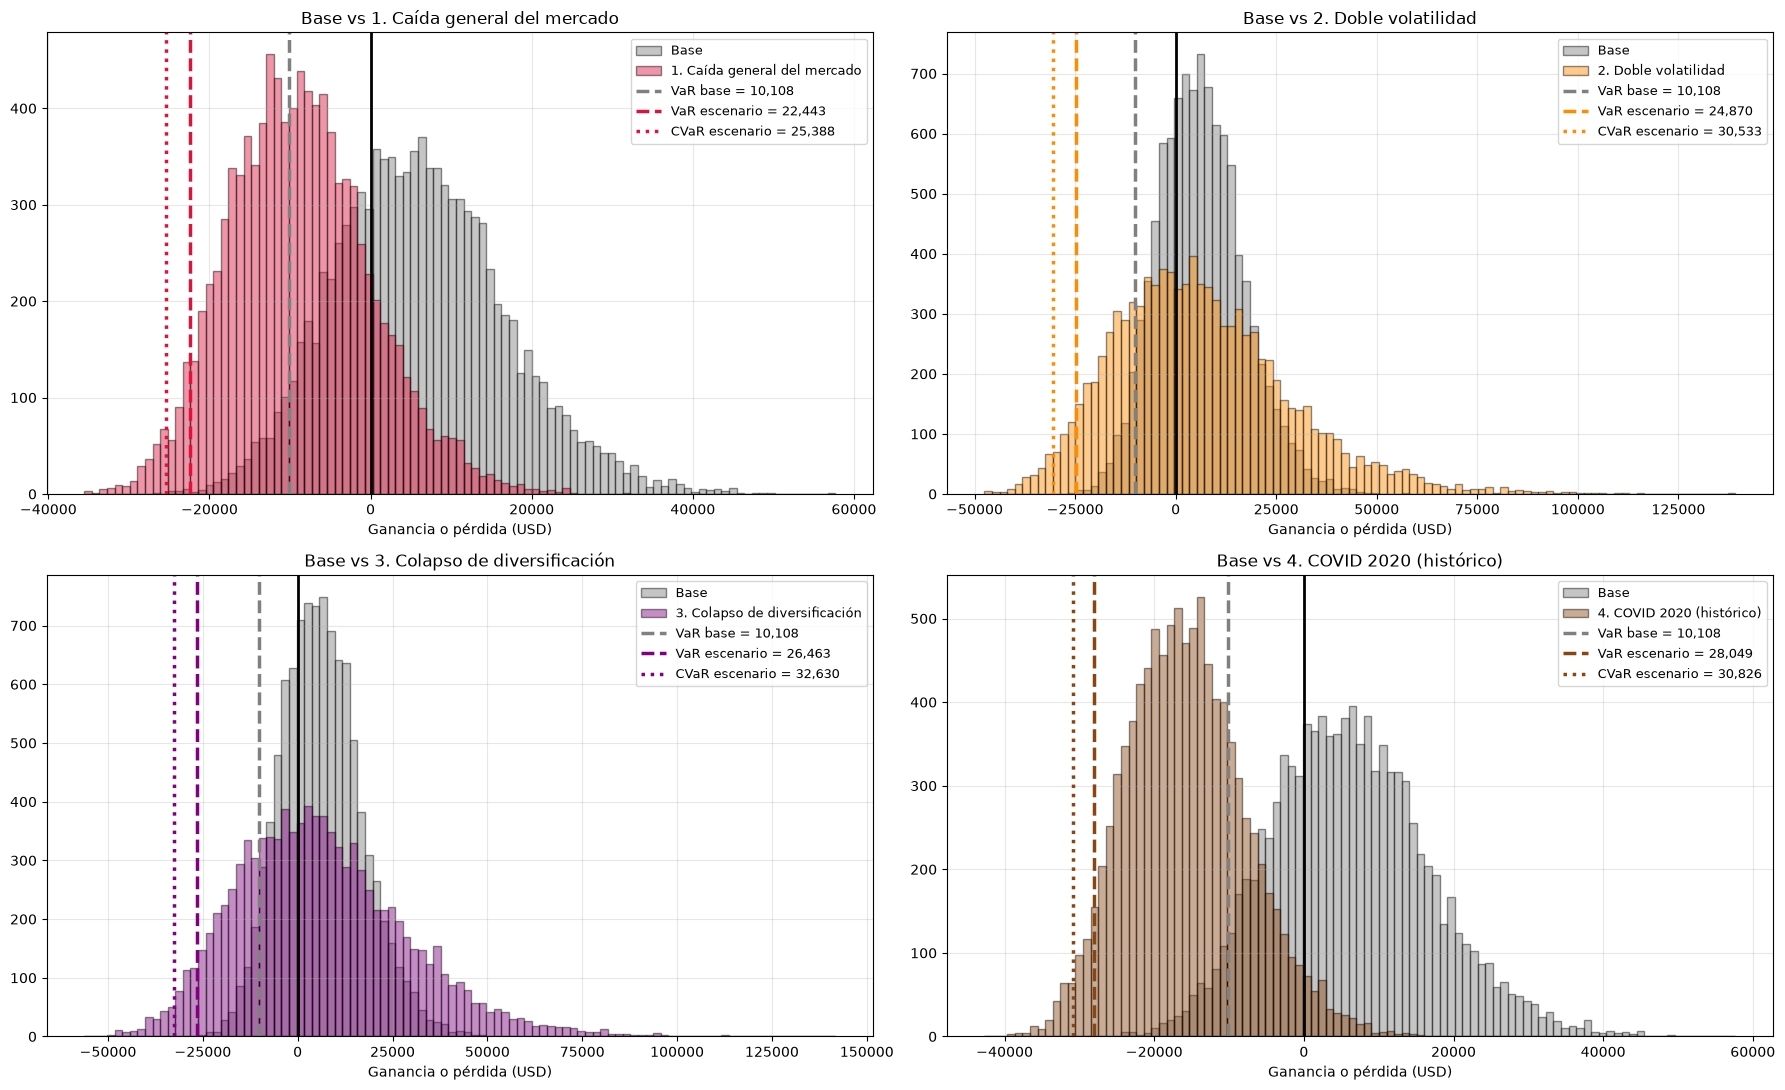

In [40]:
pnl_base = VT - V0
colores_e = ["crimson", "darkorange", "purple", "saddlebrown"]

fig, axes = plt.subplots(2, 2, figsize=(18, 11))
for ax, (nombre, VT_e), color in zip(axes.flat, list(escenarios.items())[1:], colores_e):
    pnl_e = VT_e - V0
    bins = np.linspace(min(pnl_base.min(), pnl_e.min()), max(pnl_base.max(), pnl_e.max()), 100)
    var_e, cvar_e = var_cvar(VT_e)

    ax.hist(pnl_base, bins=bins, alpha=0.45, color="gray", edgecolor="black", label="Base")
    ax.hist(pnl_e, bins=bins, alpha=0.45, color=color, edgecolor="black", label=nombre)
    ax.axvline(0, color="black", lw=2)
    ax.axvline(-VaR_base, color="gray", ls="--", lw=2.5, label=f"VaR base = {VaR_base:,.0f}")
    ax.axvline(-var_e, color=color, ls="--", lw=2.5, label=f"VaR escenario = {var_e:,.0f}")
    ax.axvline(-cvar_e, color=color, ls=":", lw=2.5, label=f"CVaR escenario = {cvar_e:,.0f}")
    ax.set_title(f"Base vs {nombre}")
    ax.set_xlabel("Ganancia o pérdida (USD)")
    ax.legend(fontsize=9)

plt.tight_layout()
plt.show()

### ¿Qué observamos?

Los cuatro escenarios afectan la distribución de forma distinta:

- **Caída del mercado y COVID desplazan toda la distribución a la izquierda** sin cambiar mucho su forma, porque son choques que se aplican a todos los escenarios. Por eso su CVaR queda cerca de su VaR (diferencias de alrededor de 3,000 USD).
- **Doble volatilidad y colapso de diversificación abren la distribución hacia los dos lados**, manteniendo el centro casi igual. La cola izquierda se alarga mucho, y la distancia entre VaR y CVaR es mayor (de 5,700 a 6,200 USD): no solo se pierde más, sino que las pérdidas extremas son más extremas.

### VaR y CVaR por escenario

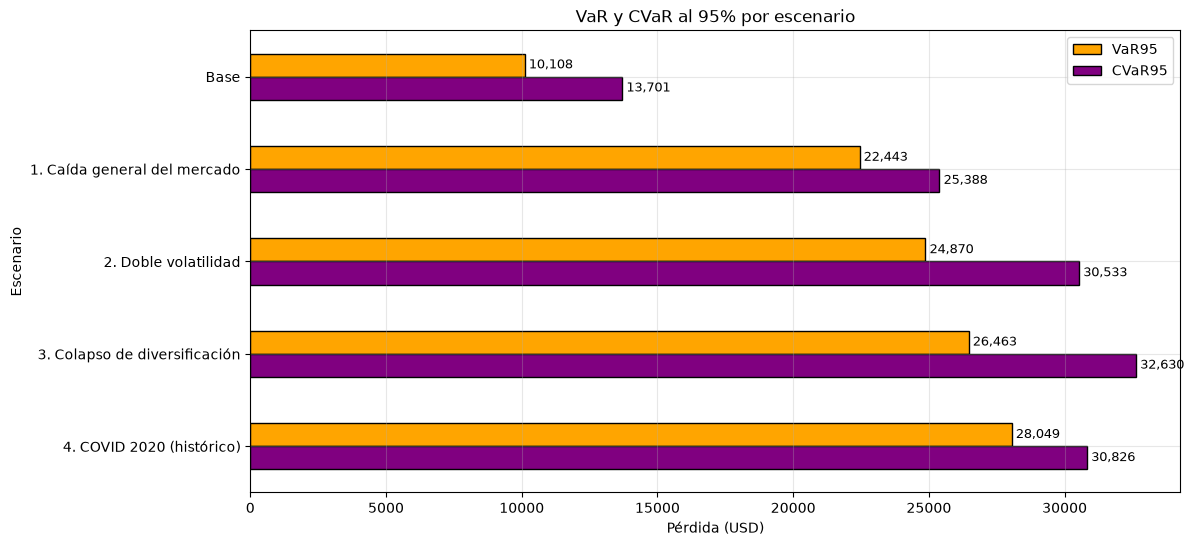

In [41]:
ax = tabla_stress[["VaR95", "CVaR95"]].plot(kind="barh", figsize=(12, 6),
                                             color=["orange", "purple"], edgecolor="black")
for barras in ax.containers:
    ax.bar_label(barras, fmt="{:,.0f}", fontsize=9, padding=3)
ax.invert_yaxis()
ax.set_xlabel("Pérdida (USD)")
ax.set_title("VaR y CVaR al 95% por escenario")
plt.show()

### ¿Qué observamos?

Por CVaR, el escenario más severo es el **colapso de diversificación (32,630 USD)**, seguido del COVID (30,826 USD) y de la doble volatilidad (30,533 USD). Por VaR, el más severo es el **COVID (28,049 USD)**.

La lección es que, para este portafolio, **el riesgo más peligroso no es que un activo caiga, sino que todos caigan juntos.** La baja correlación entre los activos es la razón por la que el portafolio tiene un riesgo tan bajo en el escenario base, y es precisamente lo que desaparece en una crisis.

---

# 6. Conclusiones

### ¿Invertiríamos en este portafolio?

**Sí, para un inversionista con perfil moderado y un horizonte de al menos varios años, de preferencia con los pesos optimizados de la sección 7.**

A favor:
- **La diversificación funciona muy bien.** Con una correlación promedio de 0.075 entre los activos, el portafolio tiene una volatilidad de 10.7% (menos que cualquiera de sus componentes y que el S&P 500) y su peor caída en los últimos tres años fue de solo 10%.
- **El riesgo base es moderado:** VaR 95% de 10.1% y CVaR 95% de 13.7% de la inversión, con un rendimiento esperado de 6.2%.
- **Resiste razonablemente las crisis.** En la peor prueba de estrés (COVID), el VaR llega a 28% de la inversión: una pérdida fuerte, pero menor que la caída de 34% del S&P 500 en ese episodio.

En contra, y por eso no es para cualquier inversionista:
- **La prima sobre la tasa libre de riesgo es pequeña:** con CAPM, el portafolio espera 6.2% contra 4.15% de los T-bills, unos 2 puntos porcentuales al año.
- **Hay 29% de probabilidad de perder en un año dado**, y en una crisis las pérdidas pueden llegar a 25% o 30%. Quien necesite el dinero en un año, o no tolere ver una pérdida así, estaría mejor en T-bills.

### ¿Cuál fue el principal factor de riesgo?

**La exposición al mercado accionario concentrada en JPM y MSFT, combinada con el riesgo de que las correlaciones suban en una crisis.**

- **En condiciones normales,** JPM y MSFT son los únicos activos con beta cercana a 1. Con 28.6% del dinero, aportan el 40% de la varianza y el 39% del CVaR.
- **En condiciones de estrés,** el factor dominante es la **pérdida de la diversificación.** El escenario de colapso de diversificación produce la mayor pérdida posible (56,244 USD) y el mayor CVaR (32,630 USD), y el COVID mostró que en una crisis real incluso activos defensivos como JNJ y XOM cayeron 25% y 48%. La baja correlación que hace tan estable al portafolio es también su punto más frágil.

### ¿Qué limitación importante tiene el modelo?

1. **Supone rendimientos normales.** Los datos tienen colas pesadas: los días extremos fueron de 3 a 5 veces más frecuentes de lo que predice una normal. El VaR y el CVaR del modelo subestiman la probabilidad de pérdidas extremas.
2. **Supone volatilidad y correlación constantes.** La volatilidad móvil cambió hasta 4 veces y las correlaciones se dispararon en abril de 2025. El modelo usa un promedio de 3 años que no captura esos cambios, y por eso fue necesario complementarlo con pruebas de estrés.
3. **El resultado depende críticamente de la tendencia supuesta.** Con la media histórica el portafolio esperaba +21.5% y el VaR era negativo; con CAPM espera +6.1% y el VaR es de 10,108 USD. El riesgo medido cambió por completo solo por el supuesto del rendimiento esperado, que es justamente el parámetro más difícil de estimar.
4. **Las betas se estiman en tiempos normales.** El escenario por beta predijo una caída promedio de 14%, y en el COVID real fue de 20.5%.

Ninguna de estas limitaciones invalida el análisis, pero todas van en la misma dirección: **el modelo tiende a subestimar el riesgo en situaciones extremas.** Por eso el VaR y el CVaR deben leerse junto con las pruebas de estrés, no solos.

---

# 7. Extra: optimización de los pesos

### Tipo de cliente

Se plantea un **cliente moderado**: un inversionista que busca crecimiento, pero que no está dispuesto a aceptar cualquier pérdida extrema a cambio de más rendimiento. Para él no basta con mirar la volatilidad, que castiga igual las subidas que las bajadas; lo que le preocupa es **cuánto puede perder en los años malos**. Por eso la medida de riesgo es el **CVaR al 95%**.

### Función de costo

$$\max_{w}\;\; E[R_p(w)] - \lambda\, \text{CVaR}_{95\%}(w)$$

sujeto a:

$$\sum_i w_i = 1, \qquad 0 \le w_i \le 35\%$$

- $\lambda$ es la **aversión a pérdidas extremas**. Con $\lambda = 0$ el cliente solo busca rendimiento (agresivo); con $\lambda$ muy grande solo busca minimizar el CVaR (conservador). El cliente moderado usa $\lambda = 0.25$: está dispuesto a aceptar hasta 4 dólares más de pérdida promedio en el peor 5% de los años a cambio de 1 dólar más de ganancia esperada. Como referencia, un cliente conservador con $\lambda = 1$ exige que cada dólar de riesgo de cola se compense con un dólar de rendimiento, lo que en la práctica lo lleva casi al portafolio de mínimo CVaR.
- **Sin ventas en corto** ($w_i \ge 0$) y **máximo 35% por activo**, para que el resultado siga siendo un portafolio diversificado y no se concentre en el activo con mejor rendimiento histórico.

### Cómo se resuelve: formulación de Rockafellar y Uryasev

El CVaR de los escenarios simulados se puede escribir como un problema lineal. Con los $M$ escenarios de rendimiento $r_s$ de la simulación base:

$$\text{CVaR}_{95\%}(w) = \min_{\alpha}\;\; \alpha + \frac{1}{0.05\, M}\sum_{s=1}^{M} \max\left(0,\; -r_s^T w - \alpha\right)$$

Al introducir variables auxiliares $u_s \ge -r_s^T w - \alpha$, $u_s \ge 0$, todo el problema queda lineal y se resuelve de forma exacta con `scipy.optimize.linprog`. En el óptimo, $\alpha$ es el VaR del portafolio.

### Datos y funciones de optimización

In [42]:
r_esc = ST / S0.values - 1                 # rendimiento de cada activo en cada escenario
mu_hat = r_esc.mean(axis=0)
alpha_cvar = 0.05
w_max = 0.35


def optimizar(lam=None, rend_min=None, escenarios=r_esc):
    """Rockafellar-Uryasev. Con lam: max E[R] - lam * CVaR.
    Con rend_min: min CVaR sujeto a E[R] >= rend_min."""
    n = escenarios.shape[0]
    media = escenarios.mean(axis=0)
    coef_cola = 1 / (alpha_cvar * n)

    if lam is not None:
        c = np.concatenate([-media, [lam], np.full(n, lam * coef_cola)])
    else:
        c = np.concatenate([np.zeros(k), [1.0], np.full(n, coef_cola)])

    # u_s >= -r_s·w - α   <=>   -r_s·w - α - u_s <= 0
    A_ub = sparse.hstack([sparse.csr_matrix(-escenarios),
                          sparse.csr_matrix(-np.ones((n, 1))),
                          -sparse.identity(n, format="csr")]).tocsr()
    b_ub = np.zeros(n)
    if rend_min is not None:
        fila = sparse.csr_matrix(np.concatenate([-media, [0.0], np.zeros(n)]))
        A_ub = sparse.vstack([A_ub, fila]).tocsr()
        b_ub = np.append(b_ub, -rend_min)

    A_eq = sparse.csr_matrix(np.concatenate([np.ones(k), [0.0], np.zeros(n)]))
    limites = [(0, w_max)] * k + [(None, None)] + [(0, None)] * n

    sol = linprog(c, A_ub=A_ub, b_ub=b_ub, A_eq=A_eq, b_eq=[1.0],
                  bounds=limites, method="highs")
    return sol.x[:k]


def evaluar(pesos, escenarios=r_esc):
    rp = escenarios @ pesos
    var, cvar = var_cvar(V0 * (1 + rp))
    return {"E[R] (%)": rp.mean() * 100, "Volatilidad (%)": rp.std() * 100,
            "VaR95 (USD)": var, "CVaR95 (USD)": cvar,
            "E[R] / CVaR": rp.mean() * V0 / cvar}

### Sensibilidad al parámetro λ

Antes de fijar $\lambda = 0.25$, se resuelve el problema para varios valores, para ver cómo cambia el portafolio desde el perfil agresivo ($\lambda = 0$) hasta el conservador ($\lambda \ge 1$).

In [43]:
lambdas = [0, 0.1, 0.25, 0.5, 1, 2, 5]
filas = []
for lam in lambdas:
    pesos = optimizar(lam=lam)
    fila = {"λ": lam, **{t: p * 100 for t, p in zip(tickers, pesos)}, **evaluar(pesos)}
    filas.append(fila)

sensibilidad = pd.DataFrame(filas).set_index("λ")
sensibilidad.round(2)

,MSFT,JPM,JNJ,COST,XOM,GLD,TLT,E[R] (%),Volatilidad (%),VaR95 (USD),CVaR95 (USD),E[R] / CVaR
λ,,,,,,,,,,,,
0.00,35.00,35.00,0.00,0.00,0.00,30.00,0.00,8.01,17.79,18372.42,23610.73,0.34
0.10,35.00,35.00,0.00,10.24,0.00,12.42,7.34,7.91,16.68,16876.50,21472.39,0.37
0.25,19.56,20.70,6.19,9.56,4.42,9.25,30.31,6.60,11.14,10090.09,13817.21,0.48
0.50,14.11,13.54,9.14,10.09,8.44,9.68,35.00,6.07,9.70,9013.83,12208.21,0.50
1.00,12.62,10.42,11.52,10.21,10.01,10.22,35.00,5.88,9.38,8774.66,11929.31,0.49
2.00,11.69,8.86,12.23,10.48,11.13,10.61,35.00,5.78,9.27,8658.65,11853.12,0.49
5.00,11.23,7.88,13.07,10.46,11.83,10.53,35.00,5.72,9.21,8680.49,11832.12,0.48


### ¿Qué observamos?

- **Con $\lambda = 0$ (agresivo)** el optimizador pone el máximo permitido en los activos de mayor rendimiento esperado: 35% en MSFT, 35% en JPM y 30% en GLD. Rinde 8.0%, pero su CVaR es de 23,611 USD, 1.7 veces el de pesos iguales.
- **Entre $\lambda = 0.1$ y $\lambda = 0.25$ el portafolio cambia de golpe:** TLT pasa de 7% a 30% y el CVaR cae de 21,472 a 13,817 USD, a cambio de solo 1.3 puntos de rendimiento. A partir de ese punto, seguir reduciendo el riesgo cuesta cada vez más rendimiento.
- **Con $\lambda \ge 1$ (conservador)** el portafolio prácticamente deja de cambiar: TLT al máximo (35%) y el resto repartido de forma casi igual, con un rendimiento de alrededor de 5.8% y un CVaR cercano a 11,900 USD.

El cliente moderado ($\lambda = 0.25$) queda justo después del cambio brusco: aprovecha casi toda la reducción de riesgo que da TLT, pero conserva una exposición importante a MSFT y JPM para seguir creciendo. $\lambda = 0.5$ tiene un cociente rendimiento / CVaR ligeramente mejor (0.50 contra 0.48), pero sacrifica medio punto de rendimiento esperado, algo que un cliente que busca crecimiento no estaría dispuesto a dar.

### Portafolio óptimo del cliente moderado

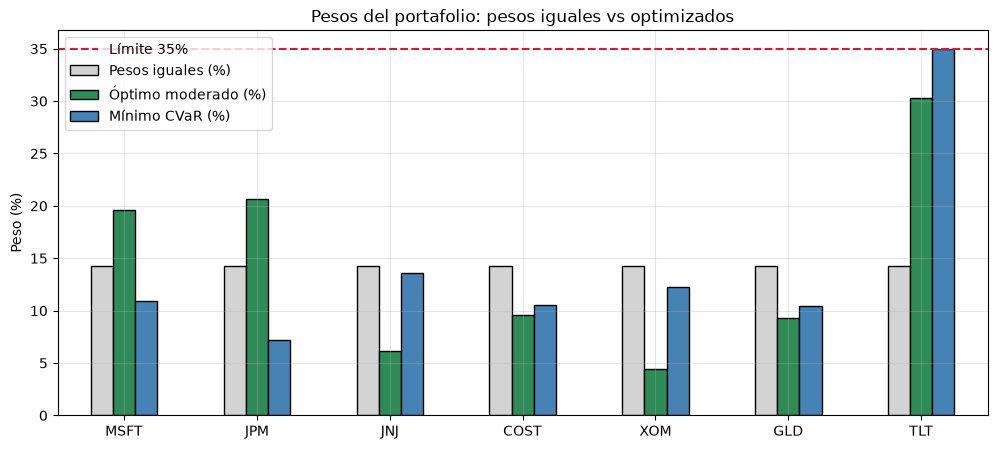

,Pesos iguales (%),Óptimo moderado (%),Mínimo CVaR (%)
MSFT,14.29,19.56,10.91
JPM,14.29,20.70,7.24
JNJ,14.29,6.19,13.55
COST,14.29,9.56,10.52
XOM,14.29,4.42,12.30
GLD,14.29,9.25,10.48
TLT,14.29,30.31,35.00


In [44]:
lam_moderado = 0.25
w_opt  = optimizar(lam=lam_moderado)
w_minc = optimizar(lam=1000)               # mínimo CVaR (perfil conservador extremo)

pesos_tabla = pd.DataFrame({"Pesos iguales (%)": w * 100,
                            "Óptimo moderado (%)": w_opt * 100,
                            "Mínimo CVaR (%)": w_minc * 100}, index=tickers)

ax = pesos_tabla.plot(kind="bar", figsize=(12, 5), rot=0, edgecolor="black",
                      color=["lightgray", "seagreen", "steelblue"])
ax.axhline(w_max * 100, color="crimson", ls="--", lw=1.5, label="Límite 35%")
ax.set_ylabel("Peso (%)")
ax.set_title("Pesos del portafolio: pesos iguales vs optimizados")
ax.legend()
plt.show()

pesos_tabla.round(2)

### ¿Qué observamos?

El portafolio óptimo del cliente moderado:

- **Concentra el crecimiento en MSFT (19.6%) y JPM (20.7%)**, los dos activos con mayor rendimiento esperado por CAPM.
- **Usa TLT (30.3%) como ancla.** Es el activo que menos aporta al riesgo y el que mejor se comportó en el COVID.
- **Reduce los activos que aportan riesgo con poco rendimiento esperado**, como XOM (4.4%) y JNJ (6.2%), que por su beta casi nula tienen rendimientos CAPM cercanos a la tasa libre de riesgo.

El portafolio de mínimo CVaR, en cambio, reparte el riesgo casi por igual y pone el máximo en TLT.

### Frontera eficiente rendimiento vs CVaR

Para cada nivel de rendimiento esperado se busca el portafolio con menor CVaR. La curva resultante es la frontera eficiente: ningún portafolio puede estar arriba y a la izquierda de ella.

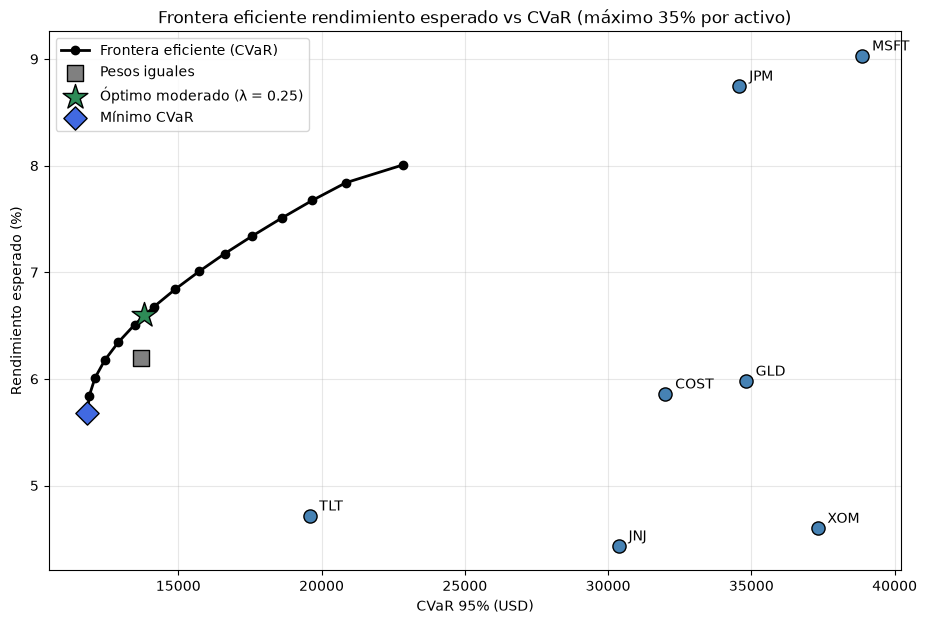

In [45]:
orden_mu = np.sort(mu_hat)[::-1]
rend_max = w_max * orden_mu[0] + w_max * orden_mu[1] + (1 - 2 * w_max) * orden_mu[2]
objetivos = np.linspace((r_esc @ w_minc).mean(), rend_max * 0.999, 15)

frontera = []
for objetivo in objetivos:
    pesos = optimizar(rend_min=objetivo)
    ev = evaluar(pesos)
    frontera.append((ev["CVaR95 (USD)"], ev["E[R] (%)"]))
frontera = np.array(frontera)

fig, ax = plt.subplots(figsize=(11, 7))
ax.plot(frontera[:, 0], frontera[:, 1], "o-", color="black", lw=2, label="Frontera eficiente (CVaR)")

for i, t in enumerate(tickers):
    ev = evaluar(np.eye(k)[i])
    ax.scatter(ev["CVaR95 (USD)"], ev["E[R] (%)"], s=90, color="steelblue", edgecolor="black", zorder=3)
    ax.annotate(t, (ev["CVaR95 (USD)"], ev["E[R] (%)"]), textcoords="offset points",
                xytext=(7, 4), fontsize=10)

for pesos, nombre, color, marca in [(w, "Pesos iguales", "gray", "s"),
                                    (w_opt, f"Óptimo moderado (λ = {lam_moderado})", "seagreen", "*"),
                                    (w_minc, "Mínimo CVaR", "royalblue", "D")]:
    ev = evaluar(pesos)
    ax.scatter(ev["CVaR95 (USD)"], ev["E[R] (%)"], s=350 if marca == "*" else 140,
               marker=marca, color=color, edgecolor="black", zorder=4, label=nombre)

ax.set_xlabel("CVaR 95% (USD)")
ax.set_ylabel("Rendimiento esperado (%)")
ax.set_title("Frontera eficiente rendimiento esperado vs CVaR (máximo 35% por activo)")
ax.legend()
plt.show()

### ¿Qué observamos?

- **El portafolio de pesos iguales queda por debajo de la frontera:** con el mismo CVaR (alrededor de 13,700 USD) se puede obtener cerca de 6.5% en lugar de 6.2%. No es un mal portafolio, pero no es eficiente.
- **El óptimo moderado está sobre la frontera**, prácticamente con el mismo riesgo de cola que pesos iguales y más rendimiento.
- **Ningún activo individual se acerca a la frontera:** cada uno tiene un CVaR de entre 19,600 y 38,900 USD, mientras que la frontera arranca en 11,800 USD. Es la diversificación vista desde otro ángulo.
- La frontera se aplana a la derecha: pasar de 7% a 8% de rendimiento esperado exige aceptar unos 7,000 USD más de CVaR.

### Validación fuera de muestra

El optimizador eligió los pesos viendo los mismos 10,000 escenarios con los que se evalúa, así que podría estar "ajustado" a ellos. Se evalúan los dos portafolios en 10,000 escenarios nuevos que el optimizador no vio.

In [46]:
# Escenarios nuevos que el optimizador no vio
np.random.seed(2027)
ST_fuera = precios_finales(np.random.normal(0, 1, [M, k]))
r_fuera = ST_fuera / S0.values - 1

validacion = pd.DataFrame({
    "Pesos iguales (dentro de muestra)": evaluar(w),
    "Óptimo moderado (dentro de muestra)": evaluar(w_opt),
    "Pesos iguales (fuera de muestra)": evaluar(w, r_fuera),
    "Óptimo moderado (fuera de muestra)": evaluar(w_opt, r_fuera),
}).T
validacion.round(2)

,E[R] (%),Volatilidad (%),VaR95 (USD),CVaR95 (USD),E[R] / CVaR
Pesos iguales (dentro de muestra),6.19,10.66,10108.11,13701.44,0.45
Óptimo moderado (dentro de muestra),6.60,11.14,10090.09,13817.21,0.48
Pesos iguales (fuera de muestra),6.27,10.49,10078.23,13220.74,0.47
Óptimo moderado (fuera de muestra),6.66,11.00,10033.33,13358.09,0.50


### ¿Qué observamos?

- **Dentro de muestra**, el óptimo moderado rinde 6.60% contra 6.19% de pesos iguales, con un VaR casi idéntico (10,090 contra 10,108 USD) y un CVaR apenas mayor (13,817 contra 13,701 USD).
- **Fuera de muestra el resultado se sostiene:** 6.66% contra 6.27%, con VaR y CVaR prácticamente iguales a los de pesos iguales. El optimizador no se "ajustó" a los escenarios que vio.
- **Resultado:** el óptimo moderado gana alrededor de **0.4 puntos porcentuales de rendimiento esperado al año sin aumentar el riesgo de cola**, y, fuera de muestra, su cociente rendimiento / CVaR mejora de 0.47 a 0.50.

### El portafolio óptimo en las pruebas de estrés

In [47]:
def valor_final(pesos, ST_esc):
    return V0 * (ST_esc / S0.values) @ pesos

escenarios_st = {"Base": ST, "1. Caída general del mercado": ST_1,
                 "2. Doble volatilidad": ST_2, "3. Colapso de diversificación": ST_3,
                 "4. COVID 2020 (histórico)": ST_4}

filas = []
for nombre, ST_e in escenarios_st.items():
    var_i, cvar_i = var_cvar(valor_final(w, ST_e))
    var_o, cvar_o = var_cvar(valor_final(w_opt, ST_e))
    filas.append({"Escenario": nombre,
                  "VaR95 pesos iguales": var_i, "VaR95 óptimo": var_o,
                  "CVaR95 pesos iguales": cvar_i, "CVaR95 óptimo": cvar_o})

stress_opt = pd.DataFrame(filas).set_index("Escenario")
stress_opt.round(2)

,VaR95 pesos iguales,VaR95 óptimo,CVaR95 pesos iguales,CVaR95 óptimo
Escenario,,,,
Base,10108.11,10090.09,13701.44,13817.21
1. Caída general del mercado,22443.31,24227.80,25387.67,27115.97
2. Doble volatilidad,24870.06,24838.61,30532.55,30593.56
3. Colapso de diversificación,26463.27,24733.77,32630.01,30692.15
4. COVID 2020 (histórico),28048.65,22997.02,30825.92,25866.19


### ¿Qué observamos?

El óptimo moderado no es mejor en todos los escenarios, y eso es importante decirlo:

- **Es peor en una caída general del mercado medida por beta** (VaR de 24,228 contra 22,443 USD), porque tiene más MSFT y JPM, los activos de beta alta.
- **Es igual con doble volatilidad.**
- **Es mejor con el colapso de diversificación** (VaR de 24,734 contra 26,463 USD), porque el 30% en TLT, el activo menos volátil, limita la pérdida cuando todo se mueve junto.
- **Es claramente mejor en el COVID:** VaR de 22,997 contra 28,049 USD y CVaR de 25,866 contra 30,826 USD. En esa crisis los bonos subieron 14% y XOM y JNJ, a los que el óptimo les quitó peso, cayeron mucho.

### Conclusiones de la optimización

1. **Formular los pesos como un problema de optimización mejora el portafolio de forma medible:** con el mismo riesgo de cola que pesos iguales, el óptimo moderado gana alrededor de 0.4 puntos porcentuales de rendimiento esperado al año, y el resultado se sostiene con escenarios nuevos.
2. **La elección de $\lambda$ es la decisión clave**, porque traduce el perfil del cliente a números. La tabla de sensibilidad muestra que el mismo problema da desde un portafolio agresivo (35% MSFT, 35% JPM, 30% GLD) hasta uno conservador (35% TLT y el resto repartido), con un cambio brusco alrededor de $\lambda = 0.25$.
3. **Optimizar para el escenario base no garantiza ser mejor en todas las crisis.** El óptimo resiste mejor un COVID y un colapso de la diversificación, pero sufre más en una caída del mercado guiada por la beta, por su mayor peso en MSFT y JPM. Un cliente moderado debería conocer ese intercambio antes de decidir.
4. **El óptimo es tan bueno como sus insumos.** Los pesos dependen de los rendimientos esperados de CAPM y de la matriz de covarianzas histórica. Si se hubiera optimizado con las medias históricas, el resultado habría tendido a favorecer a JPM, COST y JNJ por su desempeño pasado. El límite de 35% por activo es una protección deliberada contra ese error de estimación.